# Machine Learning Pipeline — Dataset 2 (NuHive / Kaggle)

In [1]:
import os
import time
import numpy as np
import librosa
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.decomposition import PCA
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

In [2]:
# ============ DATASET PATHS ============
DATASET_NAME = "Dataset 2 - NuHive / Kaggle"
BASE_PATH = r"D:\Queenless\archive\nuhive_processed"
FEATURE_DIR = r"D:\Queenless\kaggle_features"
LABELS = ['bee', 'nobee', 'noqueen']

train_path = os.path.join(BASE_PATH, 'train')
val_path   = os.path.join(BASE_PATH, 'val')
test_path  = os.path.join(BASE_PATH, 'test')
output_dir = FEATURE_DIR
os.makedirs(output_dir, exist_ok=True)

print(f"Dataset: {DATASET_NAME}")
print(f"Labels:  {LABELS}")

Dataset: Dataset 2 - NuHive / Kaggle
Labels:  ['bee', 'nobee', 'noqueen']


In [3]:
# ============ HELPER FUNCTIONS ============

def report_confusion(y_true, y_pred, title, folder="confusion_matrices"):
    """Plot & save confusion matrix, print accuracy, return acc."""
    acc = accuracy_score(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred)
    folder_path = Path(folder)
    folder_path.mkdir(parents=True, exist_ok=True)
    safe_title = title.lower().replace(" ", "_").replace("+", "_").replace("/", "_").replace("(", "").replace(")", "").replace(",", "")
    img_path = folder_path / f"{safe_title}.png"
    fig, ax = plt.subplots(figsize=(4, 4))
    ConfusionMatrixDisplay(cm).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(title)
    fig.tight_layout()
    fig.savefig(img_path, dpi=150)
    plt.show()
    plt.close(fig)
    print(f"{title} - Accuracy: {acc*100:.2f}%")
    print(f"Saved: {img_path}")
    return acc

def train_and_evaluate(clf, X_train, y_train, X_test, y_test,
                       model_name="Model", feature_name="Feature"):
    """Train a classifier, predict, show confusion matrix, return (acc, preds)."""
    start = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - start
    preds = clf.predict(X_test)
    title = f"{model_name} ({feature_name})"
    print(f"  Training time: {elapsed:.2f}s")
    acc = report_confusion(y_test, preds, title)
    return acc, preds

# 1. FFT (Origin)

In [4]:
# --- FFT Origin: extract raw FFT magnitude (no pre-emphasis) ---

def extract_fft_features(file_path, n_fft=2048):
    """Load audio and compute raw FFT magnitude (positive freqs only)."""
    try:
        audio, sr = librosa.load(file_path, sr=None)
        fft = np.fft.fft(audio, n=n_fft)
        fft_magnitude = np.abs(fft[:n_fft // 2])  # positive frequencies (1024 for n_fft=2048)
        return fft_magnitude
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset_fft():
    """Walk train/val/test splits, extract FFT features, encode labels."""
    base_path = BASE_PATH
    splits = {}
    for split in ['train', 'val', 'test']:
        features, raw_labels = [], []
        for label in LABELS:
            folder = os.path.join(base_path, split, label)
            if not os.path.exists(folder):
                continue
            for fname in os.listdir(folder):
                if fname.endswith('.wav'):
                    feat = extract_fft_features(os.path.join(folder, fname))
                    if feat is not None:
                        features.append(feat)
                        raw_labels.append(label)
        splits[split] = (np.array(features), raw_labels)

    # Encode labels with a shared LabelEncoder
    le = LabelEncoder()
    all_raw = splits['train'][1] + splits['val'][1] + splits['test'][1]
    le.fit(all_raw)

    result = {}
    for split in ['train', 'val', 'test']:
        feats, raw = splits[split]
        result[split] = (feats, le.transform(raw))
        print(f"  {split}: {feats.shape}")
    return result

print("Loading FFT Origin features...")
fft_data = load_dataset_fft()

Loading FFT Origin features...
  train: (9653, 1024)
  val: (1379, 1024)
  test: (2760, 1024)


In [5]:
# Merge train + val, scale
fft_train = np.vstack((fft_data['train'][0], fft_data['val'][0]))
fft_train_labels = np.hstack((fft_data['train'][1], fft_data['val'][1]))
fft_test = fft_data['test'][0]
fft_test_labels = fft_data['test'][1]

scaler_fft_origin = StandardScaler()
fft_train_scaled = scaler_fft_origin.fit_transform(fft_train)
fft_test_scaled  = scaler_fft_origin.transform(fft_test)

print(f"Train: {fft_train.shape}, Test: {fft_test.shape}")

Train: (11032, 1024), Test: (2760, 1024)


=== FFT Origin ===
  Training time: 0.03s


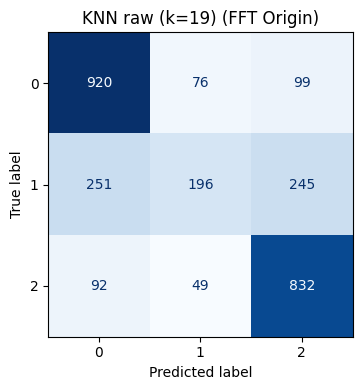

KNN raw (k=19) (FFT Origin) - Accuracy: 70.58%
Saved: confusion_matrices\knn_raw_k=19_fft_origin.png
  Training time: 0.02s


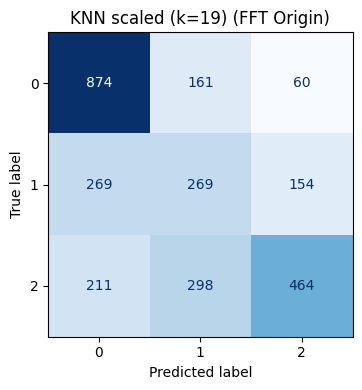

KNN scaled (k=19) (FFT Origin) - Accuracy: 58.22%
Saved: confusion_matrices\knn_scaled_k=19_fft_origin.png
  Training time: 82.14s


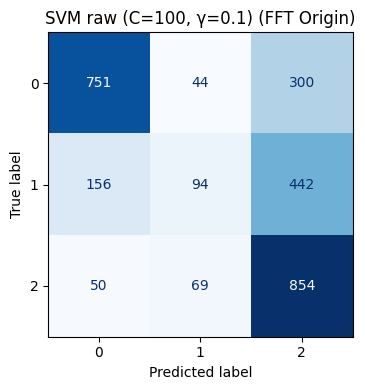

SVM raw (C=100, γ=0.1) (FFT Origin) - Accuracy: 61.56%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_fft_origin.png
  Training time: 138.70s


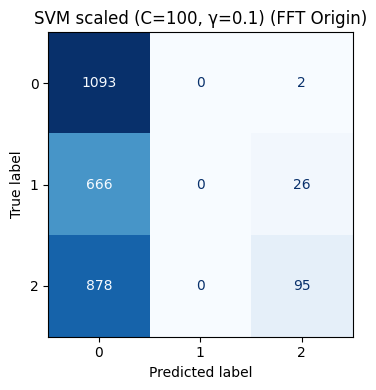

SVM scaled (C=100, γ=0.1) (FFT Origin) - Accuracy: 43.04%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_fft_origin.png
  Training time: 54.42s


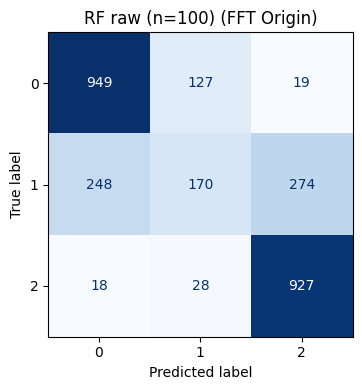

RF raw (n=100) (FFT Origin) - Accuracy: 74.13%
Saved: confusion_matrices\rf_raw_n=100_fft_origin.png
  Training time: 12.78s


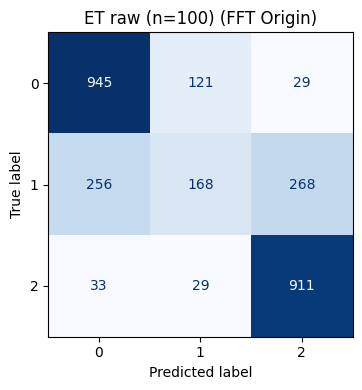

ET raw (n=100) (FFT Origin) - Accuracy: 73.33%
Saved: confusion_matrices\et_raw_n=100_fft_origin.png


(0.7333333333333333, array([0, 0, 0, ..., 2, 2, 2]))

In [6]:
print("=== FFT Origin ===")

# KNN raw (k=19)
train_and_evaluate(KNeighborsClassifier(n_neighbors=19),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "KNN raw (k=19)", "FFT Origin")

# KNN scaled (k=19)
train_and_evaluate(KNeighborsClassifier(n_neighbors=19),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "KNN scaled (k=19)", "FFT Origin")

# SVM raw
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFT Origin")

# SVM scaled
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFT Origin")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "RF raw (n=100)", "FFT Origin")

# ET raw (n=100, NO max_depth, max_features=sqrt, bootstrap=False)
train_and_evaluate(ExtraTreesClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "ET raw (n=100)", "FFT Origin")

# 2. FFTs (Pre-emphasis + Framing + Windowing + FFT)

In [7]:
# --- Signal processing pipeline for FFTs ---
# Dataset2 specific:
#   - framing: np.zeros + np.append + np.tile (same as combined section)
#   - fft_frames: np.fft.rfft (NOT np.fft.fft)
#   - log: fft_feature + 1e-8 (addition, not np.maximum)

def pre_emphasis(signal_in, pre_emph=0.97):
    """Boost high frequencies with first-order high-pass filter."""
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """Split signal into overlapping frames using np.zeros/np.append/np.tile."""
    frame_length = int(round(frame_size * sample_rate))
    frame_step   = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)
    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1

    pad_signal_length = num_frames * frame_step + frame_length
    z = np.zeros((pad_signal_length - signal_length))
    pad_signal = np.append(signal_in, z)

    indices = (np.tile(np.arange(0, frame_length), (num_frames, 1))
               + np.tile(np.arange(0, num_frames * frame_step, frame_step),
                         (frame_length, 1)).T)
    frames = pad_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing(frames):
    """Apply Hamming window to each frame."""
    frame_length = frames.shape[1]
    return frames * np.hamming(frame_length)

def fft_frames(frames, NFFT=512):
    """Compute FFT magnitude per frame using rfft."""
    return np.absolute(np.fft.rfft(frames, NFFT))

In [8]:
def compute_fft_features(signal_in, sample_rate, frame_size=0.025,
                         frame_stride=0.01, NFFT=512, apply_log=True):
    """Full pipeline: pre-emphasis → framing → windowing → FFT → mean."""
    emphasized = pre_emphasis(signal_in)
    frames = framing(emphasized, sample_rate, frame_size, frame_stride)
    windowed = windowing(frames)
    mag = fft_frames(windowed, NFFT)
    feature = np.mean(mag, axis=0)
    if apply_log:
        feature = np.log(feature + 1e-8)   # Dataset2: addition
    return feature

def load_fft_features_from_directory(directory, sample_rate=22050, NFFT=512,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached FFTs features (pkl prefix: fft3_)."""
    feat_file  = os.path.join(output_dir, f'fft3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'fft3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_fft_features(sig, sr, NFFT=NFFT))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [9]:
# Load FFTs features
ffts_train, ffts_train_labels = load_fft_features_from_directory(train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
ffts_val,   ffts_val_labels   = load_fft_features_from_directory(val_path,   NFFT=512, output_dir=output_dir, dataset_type='val')
ffts_test,  ffts_test_labels  = load_fft_features_from_directory(test_path,  NFFT=512, output_dir=output_dir, dataset_type='test')

ffts_train = np.vstack((ffts_train, ffts_val))
ffts_train_labels = np.hstack((ffts_train_labels, ffts_val_labels))

scaler_ffts = StandardScaler()
ffts_train_scaled = scaler_ffts.fit_transform(ffts_train)
ffts_test_scaled  = scaler_ffts.transform(ffts_test)

print(f"FFTs — Train: {ffts_train.shape}, Test: {ffts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs — Train: (11032, 257), Test: (2760, 257)


=== FFTs ===
  Training time: 0.01s


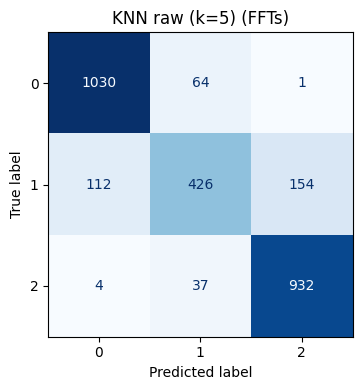

KNN raw (k=5) (FFTs) - Accuracy: 86.52%
Saved: confusion_matrices\knn_raw_k=5_ffts.png
  Training time: 0.01s


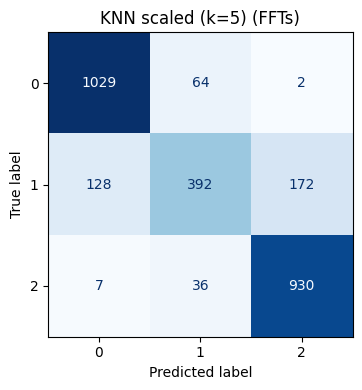

KNN scaled (k=5) (FFTs) - Accuracy: 85.18%
Saved: confusion_matrices\knn_scaled_k=5_ffts.png
  Training time: 5.02s


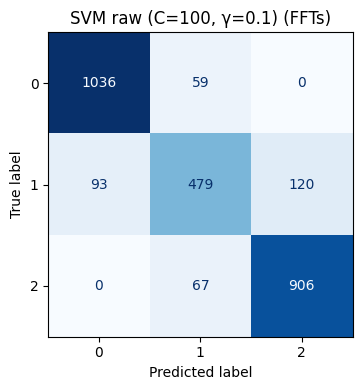

SVM raw (C=100, γ=0.1) (FFTs) - Accuracy: 87.72%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts.png
  Training time: 6.13s


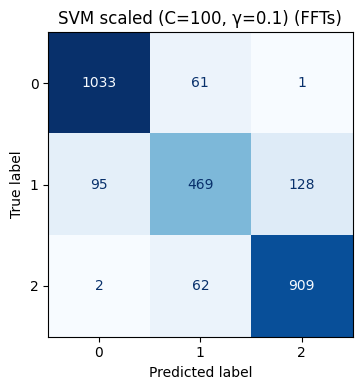

SVM scaled (C=100, γ=0.1) (FFTs) - Accuracy: 87.36%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts.png
  Training time: 21.80s


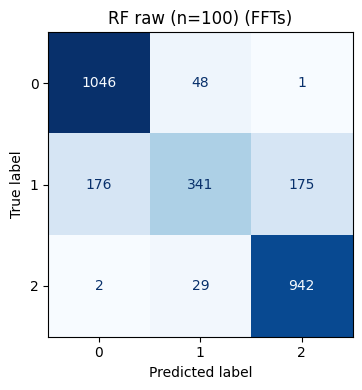

RF raw (n=100) (FFTs) - Accuracy: 84.38%
Saved: confusion_matrices\rf_raw_n=100_ffts.png
  Training time: 71.77s


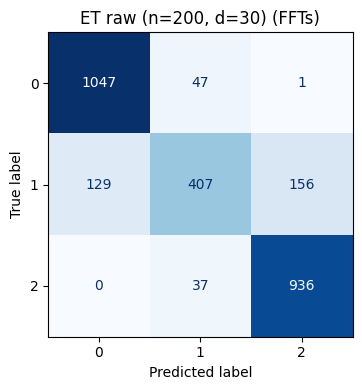

ET raw (n=200, d=30) (FFTs) - Accuracy: 86.59%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts.png


(0.8659420289855072,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [10]:
print("=== FFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "KNN raw (k=5)", "FFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "KNN scaled (k=5)", "FFTs")

# SVM raw
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs")

# SVM scaled
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "RF raw (n=100)", "FFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None,
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "ET raw (n=200, d=30)", "FFTs")

# 3. STFT

In [11]:
# --- STFT: librosa-based short-time Fourier transform ---

def compute_stft_features(signal_in, sample_rate, n_fft=2048, hop_length=512,
                          apply_log=True):
    """Compute STFT magnitude, average over time axis."""
    stft_matrix = np.abs(librosa.stft(signal_in, n_fft=n_fft, hop_length=hop_length))
    if apply_log:
        stft_matrix = np.log(stft_matrix + 1e-8)
    return np.mean(stft_matrix, axis=1)

def load_stft_features_from_directory(directory, sample_rate=22050,
                                      n_fft=2048, hop_length=512,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached STFT features (pkl prefix: stft2_)."""
    feat_file  = os.path.join(output_dir, f'stft2_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stft2_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stft_features(sig, sr, n_fft=n_fft,
                                                  hop_length=hop_length))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [12]:
# Load STFT features (n_fft=4096, hop_length=1024)
stft_train, stft_train_labels = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
stft_val,   stft_val_labels   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
stft_test,  stft_test_labels  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')

stft_train = np.vstack((stft_train, stft_val))
stft_train_labels = np.hstack((stft_train_labels, stft_val_labels))

scaler_stft = StandardScaler()
stft_train_scaled = scaler_stft.fit_transform(stft_train)
stft_test_scaled  = scaler_stft.transform(stft_test)

print(f"STFT — Train: {stft_train.shape}, Test: {stft_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFT — Train: (11032, 2049), Test: (2760, 2049)


=== STFT ===
  Training time: 0.05s


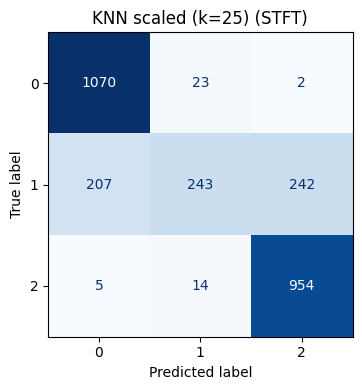

KNN scaled (k=25) (STFT) - Accuracy: 82.14%
Saved: confusion_matrices\knn_scaled_k=25_stft.png
  Training time: 49.41s


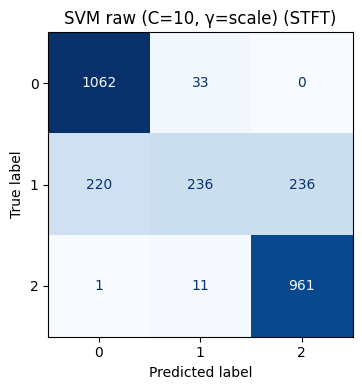

SVM raw (C=10, γ=scale) (STFT) - Accuracy: 81.85%
Saved: confusion_matrices\svm_raw_c=10_γ=scale_stft.png
  Training time: 42.30s


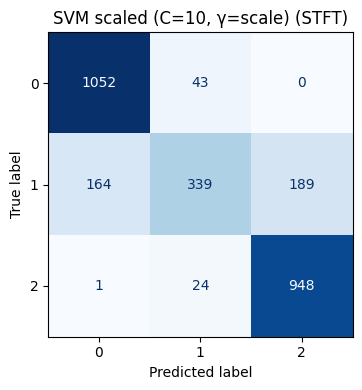

SVM scaled (C=10, γ=scale) (STFT) - Accuracy: 84.75%
Saved: confusion_matrices\svm_scaled_c=10_γ=scale_stft.png
  Training time: 60.97s


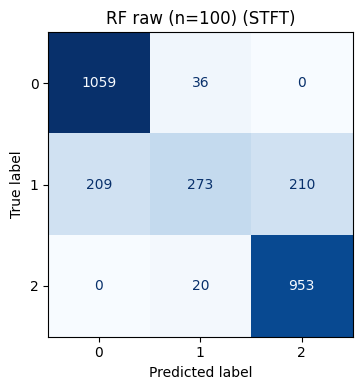

RF raw (n=100) (STFT) - Accuracy: 82.79%
Saved: confusion_matrices\rf_raw_n=100_stft.png
  Training time: 13.15s


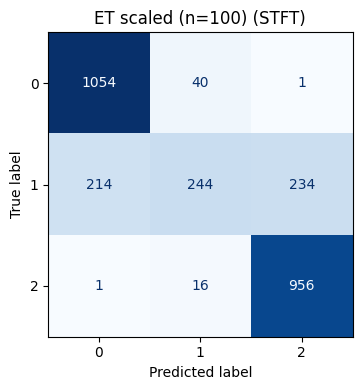

ET scaled (n=100) (STFT) - Accuracy: 81.67%
Saved: confusion_matrices\et_scaled_n=100_stft.png


(0.8166666666666667,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [13]:
print("=== STFT ===")

# KNN scaled (k=25)
train_and_evaluate(KNeighborsClassifier(n_neighbors=25),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "KNN scaled (k=25)", "STFT")

# SVM raw (C=10, γ=scale)
train_and_evaluate(SVC(C=10, kernel='rbf', gamma='scale', random_state=42),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "SVM raw (C=10, γ=scale)", "STFT")

# SVM scaled (C=10, γ=scale)
train_and_evaluate(SVC(C=10, kernel='rbf', gamma='scale', random_state=42),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "SVM scaled (C=10, γ=scale)", "STFT")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "RF raw (n=100)", "STFT")

# ET scaled (n=100)
train_and_evaluate(ExtraTreesClassifier(n_estimators=100, random_state=42),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "ET scaled (n=100)", "STFT")

# 4. FFTs + STFT

In [14]:
# --- FFTs + STFT: concat raw → scale TOGETHER (Dataset2 specific) ---
# Dataset2 scales AFTER concat (not separately like Dataset1)

fft_stft_train_raw = np.hstack((ffts_train, stft_train))
fft_stft_test_raw  = np.hstack((ffts_test,  stft_test))

scaler_fft_stft = StandardScaler()
fft_stft_train_scaled = scaler_fft_stft.fit_transform(fft_stft_train_raw)
fft_stft_test_scaled  = scaler_fft_stft.transform(fft_stft_test_raw)

fft_stft_train_labels = ffts_train_labels
fft_stft_test_labels  = ffts_test_labels

print(f"FFTs+STFT — Train: {fft_stft_train_raw.shape}, Test: {fft_stft_test_raw.shape}")

FFTs+STFT — Train: (11032, 2306), Test: (2760, 2306)


=== FFTs + STFT ===
  Training time: 0.04s


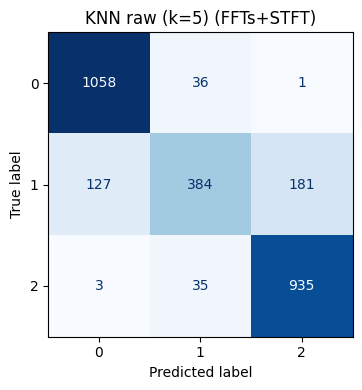

KNN raw (k=5) (FFTs+STFT) - Accuracy: 86.12%
Saved: confusion_matrices\knn_raw_k=5_ffts_stft.png
  Training time: 0.03s


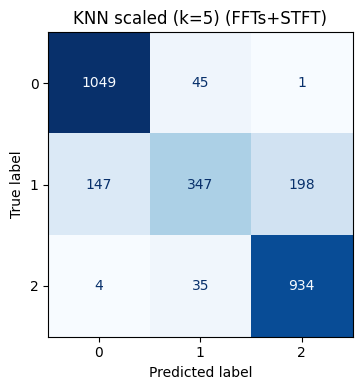

KNN scaled (k=5) (FFTs+STFT) - Accuracy: 84.42%
Saved: confusion_matrices\knn_scaled_k=5_ffts_stft.png
  Training time: 313.51s


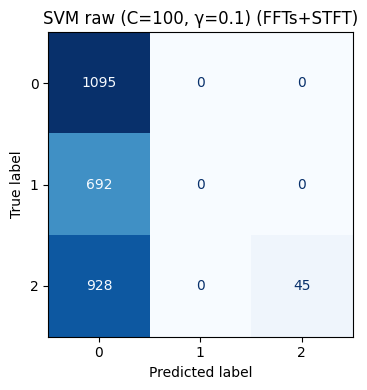

SVM raw (C=100, γ=0.1) (FFTs+STFT) - Accuracy: 41.30%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts_stft.png
  Training time: 386.80s


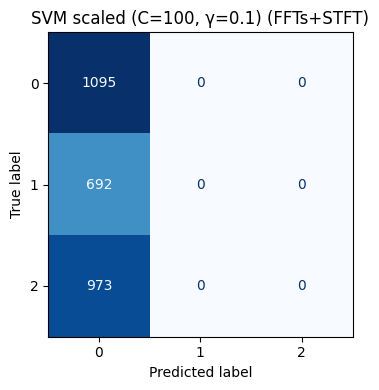

SVM scaled (C=100, γ=0.1) (FFTs+STFT) - Accuracy: 39.67%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts_stft.png
  Training time: 78.03s


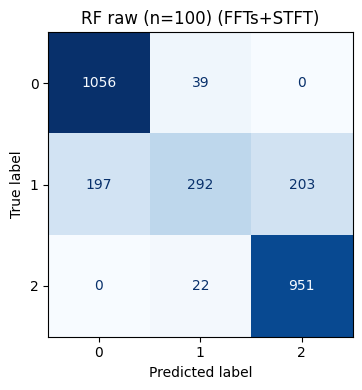

RF raw (n=100) (FFTs+STFT) - Accuracy: 83.30%
Saved: confusion_matrices\rf_raw_n=100_ffts_stft.png
  Training time: 1247.11s


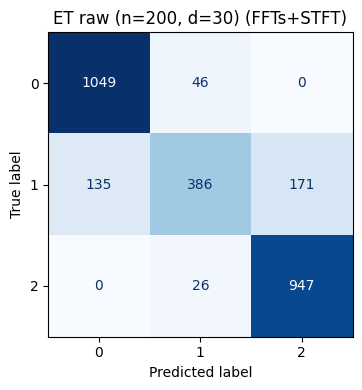

ET raw (n=200, d=30) (FFTs+STFT) - Accuracy: 86.30%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_stft.png


(0.8630434782608696,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [15]:
print("=== FFTs + STFT ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "KNN raw (k=5)", "FFTs+STFT")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "KNN scaled (k=5)", "FFTs+STFT")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFT")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFT")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "RF raw (n=100)", "FFTs+STFT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None,
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+STFT")

# 5. STFTs (Pre-emphasis + STFT per frame)

In [16]:
# --- STFTs: INLINE implementation (all ops in compute_stfts_features) ---
# Dataset2 specific: uses np.pad framing, inline pre-emphasis

def compute_stfts_features(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01,
                           n_fft=4096, apply_log=True):
    """Pre-emphasis → framing → windowing → STFT per frame → average (all inline)."""
    emphasized = np.append(signal_in[0], signal_in[1:] - 0.97 * signal_in[:-1])
    frame_length = int(round(frame_size * sample_rate))
    frame_step = int(round(frame_stride * sample_rate))
    signal_length = len(emphasized)

    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1
    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(emphasized, (0, pad_signal_length - signal_length), mode='constant')

    indices = np.arange(0, frame_length) + np.arange(0, num_frames * frame_step, frame_step)[:, None]
    frames = pad_signal[indices.astype(np.int32)]
    frames *= np.hamming(frames.shape[1])

    # STFT for each frame: take first time column
    mag_frames = []
    for frame in frames:
        stft = np.abs(librosa.stft(frame, n_fft=n_fft))
        mag_frames.append(stft[:, 0])

    mag_frames = np.array(mag_frames)
    feat = np.mean(mag_frames, axis=0)
    if apply_log:
        feat = np.log(np.maximum(feat, 1e-8))
    return feat

def load_stfts_features_from_directory(directory, sample_rate=22050, n_fft=4096,
                                       frame_size=0.025, frame_stride=0.01,
                                       output_dir=None, dataset_type='train'):
    """Extract or load cached STFTs features (pkl prefix: stfts4_)."""
    feat_file  = os.path.join(output_dir, f'stfts4_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stfts4_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            print(f"  Warning: missing folder {folder}")
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stfts_features(sig, sr, frame_size=frame_size,
                                                   frame_stride=frame_stride, n_fft=n_fft))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [17]:
stfts_train, stfts_train_labels = load_stfts_features_from_directory(train_path, n_fft=4096, output_dir=output_dir, dataset_type='train')
stfts_val,   stfts_val_labels   = load_stfts_features_from_directory(val_path,   n_fft=4096, output_dir=output_dir, dataset_type='val')
stfts_test,  stfts_test_labels  = load_stfts_features_from_directory(test_path,  n_fft=4096, output_dir=output_dir, dataset_type='test')

stfts_train = np.vstack((stfts_train, stfts_val))
stfts_train_labels = np.hstack((stfts_train_labels, stfts_val_labels))

scaler_stfts = StandardScaler()
stfts_train_scaled = scaler_stfts.fit_transform(stfts_train)
stfts_test_scaled  = scaler_stfts.transform(stfts_test)

print(f"STFTs — Train: {stfts_train.shape}, Test: {stfts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFTs — Train: (11032, 2049), Test: (2760, 2049)


=== STFTs ===
  Training time: 0.03s


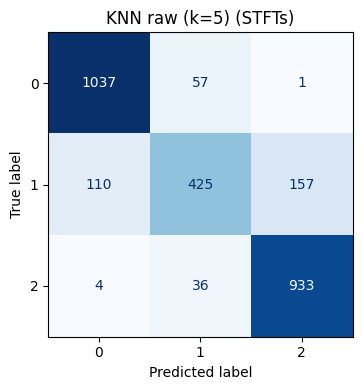

KNN raw (k=5) (STFTs) - Accuracy: 86.78%
Saved: confusion_matrices\knn_raw_k=5_stfts.png
  Training time: 0.03s


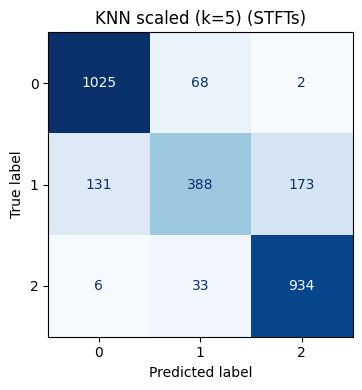

KNN scaled (k=5) (STFTs) - Accuracy: 85.04%
Saved: confusion_matrices\knn_scaled_k=5_stfts.png
  Training time: 127.20s


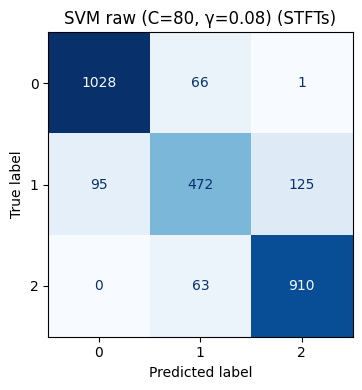

SVM raw (C=80, γ=0.08) (STFTs) - Accuracy: 87.32%
Saved: confusion_matrices\svm_raw_c=80_γ=0.08_stfts.png
  Training time: 49.51s


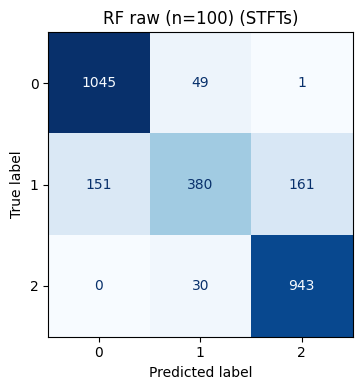

RF raw (n=100) (STFTs) - Accuracy: 85.80%
Saved: confusion_matrices\rf_raw_n=100_stfts.png
  Training time: 712.19s


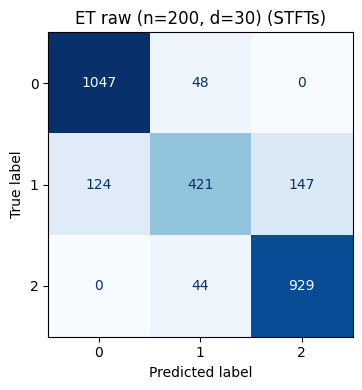

ET raw (n=200, d=30) (STFTs) - Accuracy: 86.85%
Saved: confusion_matrices\et_raw_n=200_d=30_stfts.png


(0.8684782608695653,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [18]:
print("=== STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "KNN raw (k=5)", "STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train_scaled, stfts_train_labels, stfts_test_scaled, stfts_test_labels,
                   "KNN scaled (k=5)", "STFTs")

# SVM raw (C=80, γ=0.08) — Dataset2 specific params
train_and_evaluate(SVC(C=80, kernel='rbf', gamma=0.08, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "SVM raw (C=80, γ=0.08)", "STFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "RF raw (n=100)", "STFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None,
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "ET raw (n=200, d=30)", "STFTs")

# 6. FFTs + STFTs

In [19]:
# --- Combine FFTs + STFTs ---
ffts_stfts_train = np.hstack((ffts_train, stfts_train))
ffts_stfts_test  = np.hstack((ffts_test,  stfts_test))

scaler_ffts_stfts = StandardScaler()
ffts_stfts_train_scaled = scaler_ffts_stfts.fit_transform(ffts_stfts_train)
ffts_stfts_test_scaled  = scaler_ffts_stfts.transform(ffts_stfts_test)

ffts_stfts_labels_train = ffts_train_labels
ffts_stfts_labels_test  = ffts_test_labels

print(f"FFTs+STFTs — Train: {ffts_stfts_train.shape}, Test: {ffts_stfts_test.shape}")

FFTs+STFTs — Train: (11032, 2306), Test: (2760, 2306)


=== FFTs + STFTs ===
  Training time: 0.04s


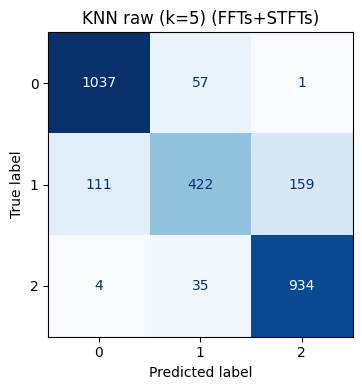

KNN raw (k=5) (FFTs+STFTs) - Accuracy: 86.70%
Saved: confusion_matrices\knn_raw_k=5_ffts_stfts.png
  Training time: 0.05s


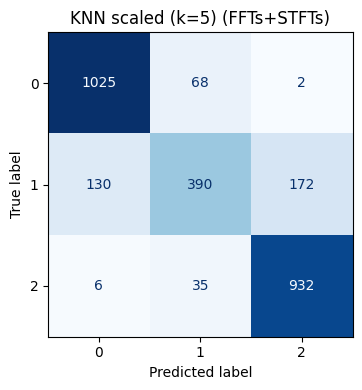

KNN scaled (k=5) (FFTs+STFTs) - Accuracy: 85.04%
Saved: confusion_matrices\knn_scaled_k=5_ffts_stfts.png
  Training time: 183.83s


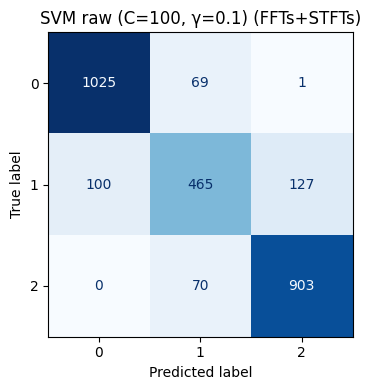

SVM raw (C=100, γ=0.1) (FFTs+STFTs) - Accuracy: 86.70%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_ffts_stfts.png
  Training time: 231.60s


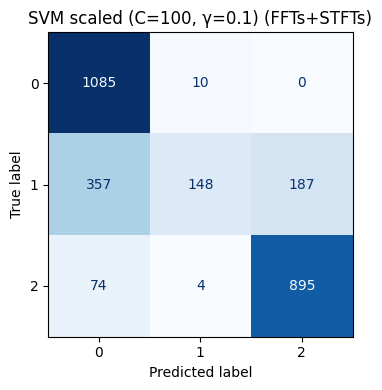

SVM scaled (C=100, γ=0.1) (FFTs+STFTs) - Accuracy: 77.10%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_ffts_stfts.png
  Training time: 57.47s


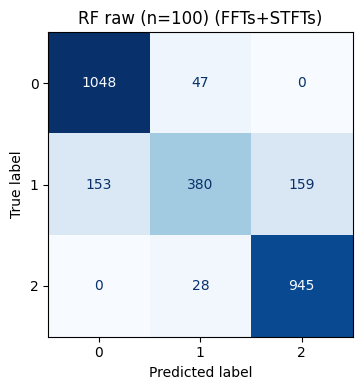

RF raw (n=100) (FFTs+STFTs) - Accuracy: 85.98%
Saved: confusion_matrices\rf_raw_n=100_ffts_stfts.png
  Training time: 809.39s


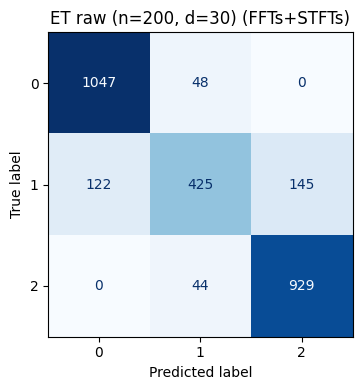

ET raw (n=200, d=30) (FFTs+STFTs) - Accuracy: 86.99%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_stfts.png


(0.869927536231884,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [20]:
print("=== FFTs + STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "KNN raw (k=5)", "FFTs+STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "KNN scaled (k=5)", "FFTs+STFTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "RF raw (n=100)", "FFTs+STFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None,
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "ET raw (n=200, d=30)", "FFTs+STFTs")

# 7. CQT

In [21]:
# --- CQT: Constant-Q Transform (no pre-emphasis) ---

def compute_cqt_features(signal_in, sample_rate, hop_length=512, fmin=None,
                         n_bins=84, bins_per_octave=12, apply_log=True):
    """Compute CQT magnitude → log → average over time → shape (n_bins,)."""
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    if apply_log:
        cqt_matrix = np.log(cqt_matrix + 1e-8)
    return np.mean(cqt_matrix, axis=1)

def load_cqt_features_from_directory(directory, sample_rate=22050, hop_length=512,
                                     fmin=None, n_bins=84, bins_per_octave=12,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached CQT features (pkl prefix: cqt_)."""
    feat_file  = os.path.join(output_dir, f'cqt_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqt_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqt_features(sig, sr, hop_length=hop_length,
                                                 fmin=fmin, n_bins=n_bins,
                                                 bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [22]:
cqt_train, cqt_train_labels = load_cqt_features_from_directory(train_path, hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='train')
cqt_val,   cqt_val_labels   = load_cqt_features_from_directory(val_path,   hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='val')
cqt_test,  cqt_test_labels  = load_cqt_features_from_directory(test_path,  hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='test')

cqt_train = np.vstack((cqt_train, cqt_val))
cqt_train_labels = np.hstack((cqt_train_labels, cqt_val_labels))

scaler_cqt = StandardScaler()
cqt_train_scaled = scaler_cqt.fit_transform(cqt_train)
cqt_test_scaled  = scaler_cqt.transform(cqt_test)

print(f"CQT — Train: {cqt_train.shape}, Test: {cqt_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQT — Train: (11032, 84), Test: (2760, 84)


=== CQT ===
  Training time: 0.01s


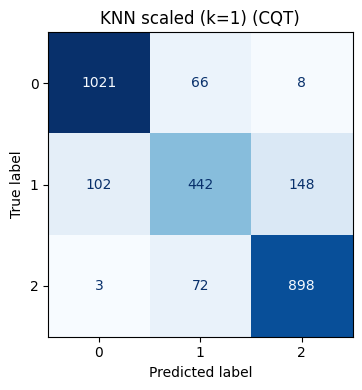

KNN scaled (k=1) (CQT) - Accuracy: 85.54%
Saved: confusion_matrices\knn_scaled_k=1_cqt.png
  Training time: 2.57s


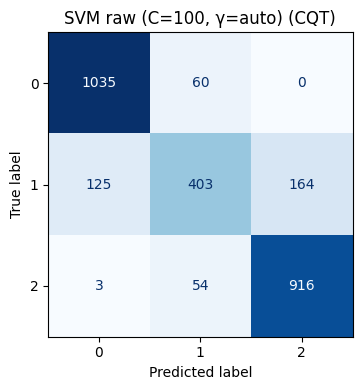

SVM raw (C=100, γ=auto) (CQT) - Accuracy: 85.29%
Saved: confusion_matrices\svm_raw_c=100_γ=auto_cqt.png
  Training time: 2.58s


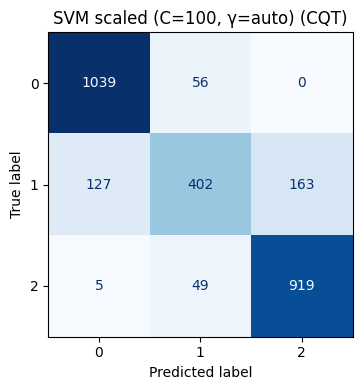

SVM scaled (C=100, γ=auto) (CQT) - Accuracy: 85.51%
Saved: confusion_matrices\svm_scaled_c=100_γ=auto_cqt.png
  Training time: 0.47s


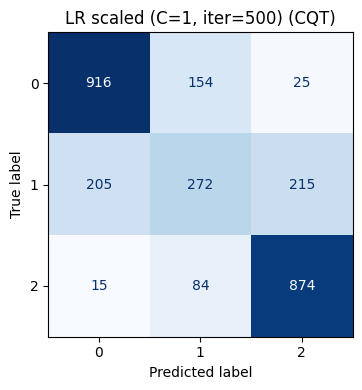

LR scaled (C=1, iter=500) (CQT) - Accuracy: 74.71%
Saved: confusion_matrices\lr_scaled_c=1_iter=500_cqt.png
  Training time: 16.39s


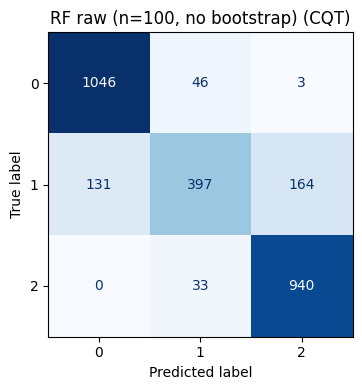

RF raw (n=100, no bootstrap) (CQT) - Accuracy: 86.34%
Saved: confusion_matrices\rf_raw_n=100_no_bootstrap_cqt.png
  Training time: 3.10s


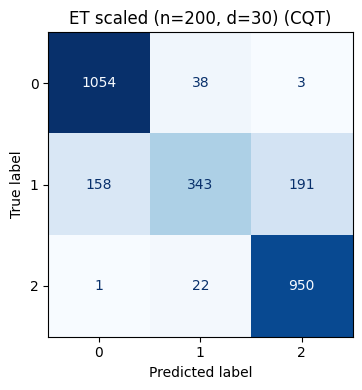

ET scaled (n=200, d=30) (CQT) - Accuracy: 85.04%
Saved: confusion_matrices\et_scaled_n=200_d=30_cqt.png


(0.8503623188405797,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [23]:
print("=== CQT ===")

# KNN scaled (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "KNN scaled (k=1)", "CQT")

# SVM raw (C=100, γ=auto)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma='auto', random_state=42),
                   cqt_train, cqt_train_labels, cqt_test, cqt_test_labels,
                   "SVM raw (C=100, γ=auto)", "CQT")

# SVM scaled (C=100, γ=auto)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma='auto', random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "SVM scaled (C=100, γ=auto)", "CQT")

# LR scaled (C=1, iter=500)
train_and_evaluate(LogisticRegression(C=1.0, max_iter=500, solver='lbfgs', random_state=None),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "LR scaled (C=1, iter=500)", "CQT")

# RF raw (bootstrap=False)
train_and_evaluate(RandomForestClassifier(n_estimators=100, bootstrap=False, random_state=42),
                   cqt_train, cqt_train_labels, cqt_test, cqt_test_labels,
                   "RF raw (n=100, no bootstrap)", "CQT")

# ET scaled (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "ET scaled (n=200, d=30)", "CQT")

# 8. CQTs (Pre-emphasis + CQT)

In [24]:
# --- CQTs: Pre-emphasis + CQT ---

def compute_cqts_features(signal_in, sample_rate, frame_size=0.025,
                          frame_stride=0.01, fmin=None, n_bins=84,
                          bins_per_octave=12, apply_log=True):
    """Pre-emphasis → CQT on full signal → average over time."""
    emphasized = pre_emphasis(signal_in)
    cqt_matrix = np.abs(librosa.cqt(emphasized, sr=sample_rate,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave,
                                    hop_length=512))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))
    return feature

def load_cqts_features_from_directory(directory, sample_rate=22050,
                                      frame_size=0.025, frame_stride=0.01,
                                      fmin=None, n_bins=84, bins_per_octave=12,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached CQTs features (pkl prefix: cqts3_)."""
    feat_file  = os.path.join(output_dir, f'cqts3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqts3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            print(f"  Warning: missing folder {folder}")
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqts_features(sig, sr, frame_size=frame_size,
                                                  frame_stride=frame_stride, fmin=fmin,
                                                  n_bins=n_bins, bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [25]:
cqts_train, cqts_train_labels = load_cqts_features_from_directory(train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
cqts_val,   cqts_val_labels   = load_cqts_features_from_directory(val_path,   n_bins=84, output_dir=output_dir, dataset_type='val')
cqts_test,  cqts_test_labels  = load_cqts_features_from_directory(test_path,  n_bins=84, output_dir=output_dir, dataset_type='test')

cqts_train = np.vstack((cqts_train, cqts_val))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))

scaler_cqts = StandardScaler()
cqts_train_scaled = scaler_cqts.fit_transform(cqts_train)
cqts_test_scaled  = scaler_cqts.transform(cqts_test)

print(f"CQTs — Train: {cqts_train.shape}, Test: {cqts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQTs — Train: (11032, 84), Test: (2760, 84)


=== CQTs ===
  Training time: 0.00s


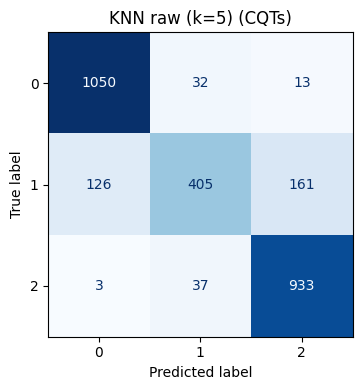

KNN raw (k=5) (CQTs) - Accuracy: 86.52%
Saved: confusion_matrices\knn_raw_k=5_cqts.png
  Training time: 0.00s


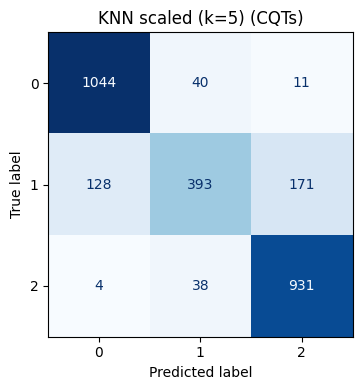

KNN scaled (k=5) (CQTs) - Accuracy: 85.80%
Saved: confusion_matrices\knn_scaled_k=5_cqts.png
  Training time: 2.37s


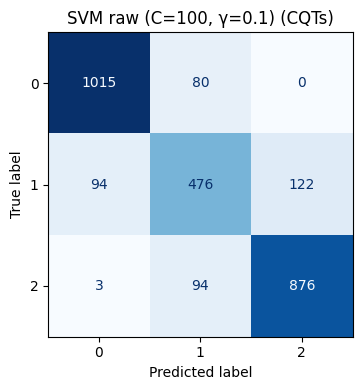

SVM raw (C=100, γ=0.1) (CQTs) - Accuracy: 85.76%
Saved: confusion_matrices\svm_raw_c=100_γ=0.1_cqts.png
  Training time: 2.44s


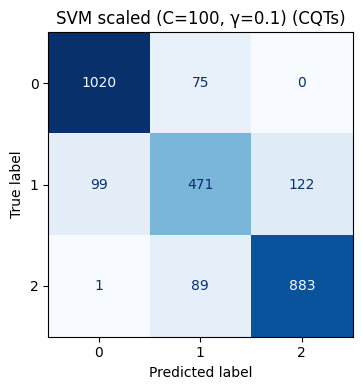

SVM scaled (C=100, γ=0.1) (CQTs) - Accuracy: 86.01%
Saved: confusion_matrices\svm_scaled_c=100_γ=0.1_cqts.png
  Training time: 10.18s


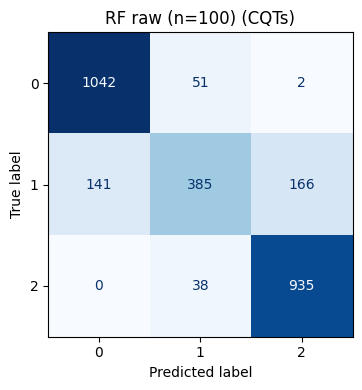

RF raw (n=100) (CQTs) - Accuracy: 85.58%
Saved: confusion_matrices\rf_raw_n=100_cqts.png
  Training time: 17.62s


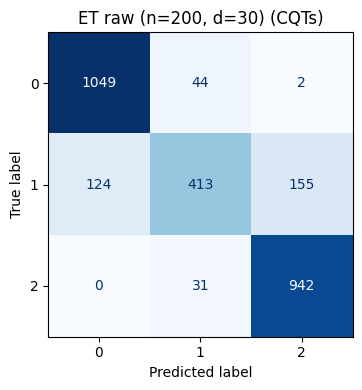

ET raw (n=200, d=30) (CQTs) - Accuracy: 87.10%
Saved: confusion_matrices\et_raw_n=200_d=30_cqts.png


(0.8710144927536232,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [26]:
print("=== CQTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "KNN raw (k=5)", "CQTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "KNN scaled (k=5)", "CQTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "CQTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "CQTs")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, criterion='gini', max_depth=None, min_samples_split=2,
                    min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features='sqrt',
                    max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=True, oob_score=False,
                    n_jobs=None, random_state=42, verbose=0, warm_start=False, class_weight=None,
                    ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "RF raw (n=100)", "CQTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, criterion='gini', max_depth=30, min_samples_split=2,
                                     min_samples_leaf=1, min_weight_fraction_leaf=0.0, max_features=None,
                                     max_leaf_nodes=None, min_impurity_decrease=0.0, bootstrap=False,
                                     n_jobs=None, random_state=42, verbose=0, warm_start=False,
                                     class_weight=None, ccp_alpha=0.0, max_samples=None, monotonic_cst=None),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "ET raw (n=200, d=30)", "CQTs")

# 9. FFTs + CQT (Combined Feature Extraction — Bartlett Window, hop/overlap framing)

In [27]:
# --- FFTs+CQT: DIFFERENT signal processing from Section 2 ---
# Dataset2 specific: framing with hop_length/overlap params, bartlett window, NFFT=2048

def pre_emphasis_combined(signal_in, pre_emph=0.97):
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing_combined(signal_in, sample_rate, frame_size=0.025, hop_length=256, overlap=0.6):
    """Framing with hop_length/overlap approach (Dataset2 specific)."""
    if frame_size <= 1:
        frame_length = int(round(frame_size * sample_rate))
    else:
        frame_length = int(frame_size)

    if hop_length is None:
        frame_step = int(frame_length * (1 - overlap))
    elif hop_length <= 1:
        frame_step = int(round(hop_length * sample_rate))
    else:
        frame_step = int(hop_length)

    frame_step = max(1, frame_step)
    signal_length = len(signal_in)
    num_frames = int(np.ceil((signal_length - frame_length) / frame_step)) + 1

    pad_signal_length = (num_frames - 1) * frame_step + frame_length
    pad_zeros = np.zeros(pad_signal_length - signal_length)
    padded_signal = np.concatenate([signal_in, pad_zeros])

    indices = (np.tile(np.arange(0, frame_length), (num_frames, 1))
               + np.tile(np.arange(0, num_frames * frame_step, frame_step), (frame_length, 1)).T)
    indices = np.minimum(indices, len(padded_signal) - 1)
    frames = padded_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing_combined(frames, window_type='bartlett'):
    """Apply bartlett window (Dataset2 specific)."""
    frame_length = frames.shape[1]
    if window_type == 'bartlett':
        window = np.bartlett(frame_length)
    elif window_type == 'hamming':
        window = np.hamming(frame_length)
    elif window_type == 'hanning':
        window = np.hanning(frame_length)
    elif window_type == 'blackman':
        window = np.blackman(frame_length)
    else:
        window = np.hamming(frame_length)
    return frames * window

def fft_frames_combined(frames, NFFT=512):
    return np.absolute(np.fft.rfft(frames, NFFT))

def compute_fft_features_combined(signal_in, sample_rate, frame_size=0.025,
                                  hop_length=512, overlap=0.6, NFFT=2048,
                                  window_type='bartlett', apply_log=True):
    emphasized = pre_emphasis_combined(signal_in)
    frames = framing_combined(emphasized, sample_rate, frame_size, hop_length, overlap)
    windowed = windowing_combined(frames, window_type)
    mag = fft_frames_combined(windowed, NFFT)
    feature = np.mean(mag, axis=0)
    if apply_log:
        feature = np.log(feature + 1e-8)
    return feature

def compute_cqt_features_combined(signal_in, sample_rate, hop_length=512, fmin=None,
                                  n_bins=84, bins_per_octave=12, apply_log=True):
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(feature + 1e-8)
    return feature

def compute_combined_features(signal_in, sample_rate, frame_size=0.025,
                              hop_length=512, overlap=0.6, NFFT=2048,
                              window_type='bartlett', fmin=None, n_bins=84,
                              bins_per_octave=12, apply_log=True):
    fft_feat = compute_fft_features_combined(signal_in, sample_rate,
                                            frame_size=frame_size, hop_length=hop_length,
                                            overlap=overlap, NFFT=NFFT,
                                            window_type=window_type, apply_log=apply_log)
    cqt_feat = compute_cqt_features_combined(signal_in, sample_rate,
                                            hop_length=hop_length, fmin=fmin,
                                            n_bins=n_bins, bins_per_octave=bins_per_octave,
                                            apply_log=apply_log)
    return np.concatenate((fft_feat, cqt_feat))

In [28]:
def load_combined_features_from_directory(directory, sample_rate=22050, NFFT=2048,
                                         hop_length=512, fmin=None, n_bins=96,
                                         bins_per_octave=12, output_dir=None,
                                         dataset_type='train'):
    hop_str = f"{hop_length}" if hop_length else "overlap0.6"
    feat_file  = os.path.join(output_dir, f'combined_features_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')
    label_file = os.path.join(output_dir, f'combined_labels_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.exists(folder):
            print(f"  Warning: {folder} not found, skipping")
            continue
        for fname in os.listdir(folder):
            if not fname.endswith(('.wav', '.mp3', '.flac', '.ogg')):
                continue
            fpath = os.path.join(folder, fname)
            try:
                sig, sr = librosa.load(fpath, sr=sample_rate)
                feat = compute_combined_features(sig, sr, hop_length=hop_length,
                                                NFFT=NFFT, fmin=fmin, n_bins=n_bins,
                                                bins_per_octave=bins_per_octave)
                features.append(feat)
                labels.append(label)
            except Exception as e:
                print(f"  Error: {fpath}: {e}")
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s — shape {features.shape}")
    return features, labels

In [29]:
# Load combined FFTs+CQT features (NFFT=2048, n_bins=96, hop=512)
combined_train, combined_train_labels = load_combined_features_from_directory(
    train_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='train')
combined_val, combined_val_labels = load_combined_features_from_directory(
    val_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='val')
combined_test, combined_test_labels = load_combined_features_from_directory(
    test_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='test')

combined_train = np.vstack((combined_train, combined_val))
combined_train_labels = np.hstack((combined_train_labels, combined_val_labels))

# PCA on FFT part only (150 components, rs=53940), keep CQT raw
def separate_fft_cqt(combined_features, nfft=2048):
    fft_dim = nfft // 2 + 1
    if combined_features.ndim == 1:
        return combined_features[:fft_dim], combined_features[fft_dim:]
    return combined_features[:, :fft_dim], combined_features[:, fft_dim:]

train_fft_part, train_cqt_part = separate_fft_cqt(combined_train, nfft=2048)
test_fft_part,  test_cqt_part  = separate_fft_cqt(combined_test,  nfft=2048)

pca_fft = PCA(n_components=150, random_state=53940)
train_fft_pca = pca_fft.fit_transform(train_fft_part)
test_fft_pca  = pca_fft.transform(test_fft_part)

# Recombine: PCA(FFT) + raw CQT = 150 + 96 = 246
combined_train_pca = np.hstack((train_fft_pca, train_cqt_part))
combined_test_pca  = np.hstack((test_fft_pca,  test_cqt_part))

scaler_combined = StandardScaler()
combined_train_scaled = scaler_combined.fit_transform(combined_train_pca)
combined_test_scaled  = scaler_combined.transform(combined_test_pca)

print(f"FFTs+CQT (PCA FFT) — Train: {combined_train_pca.shape}, Test: {combined_test_pca.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQT (PCA FFT) — Train: (11032, 246), Test: (2760, 246)


=== FFTs + CQT ===
  Training time: 0.01s


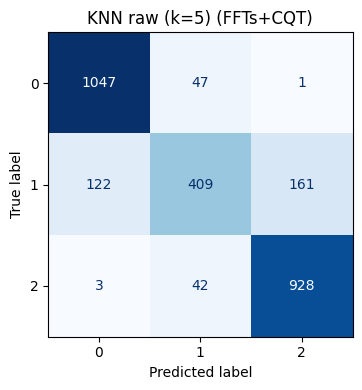

KNN raw (k=5) (FFTs+CQT) - Accuracy: 86.38%
Saved: confusion_matrices\knn_raw_k=5_ffts_cqt.png
  Training time: 0.01s


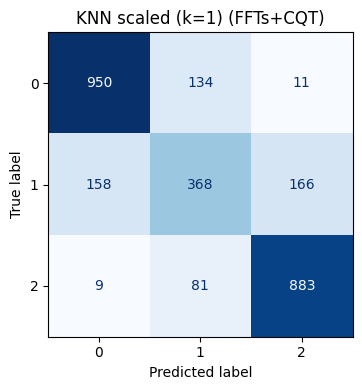

KNN scaled (k=1) (FFTs+CQT) - Accuracy: 79.75%
Saved: confusion_matrices\knn_scaled_k=1_ffts_cqt.png
  Training time: 6.44s


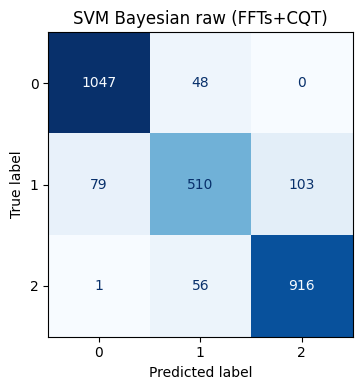

SVM Bayesian raw (FFTs+CQT) - Accuracy: 89.60%
Saved: confusion_matrices\svm_bayesian_raw_ffts_cqt.png
  Training time: 19.15s


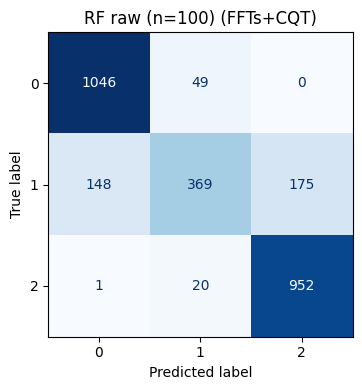

RF raw (n=100) (FFTs+CQT) - Accuracy: 85.76%
Saved: confusion_matrices\rf_raw_n=100_ffts_cqt.png
  Training time: 6.11s


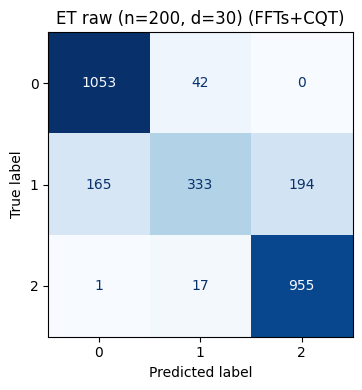

ET raw (n=200, d=30) (FFTs+CQT) - Accuracy: 84.82%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_cqt.png


(0.8481884057971014,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [30]:
print("=== FFTs + CQT ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   combined_train_pca, combined_train_labels, combined_test_pca, combined_test_labels,
                   "KNN raw (k=5)", "FFTs+CQT")

# KNN scaled (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "KNN scaled (k=1)", "FFTs+CQT")

# SVM raw (Bayesian-optimized)
train_and_evaluate(SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                       tol=0.0005319450186421158, cache_size=500, random_state=42),
                   combined_train_pca, combined_train_labels, combined_test_pca, combined_test_labels,
                   "SVM Bayesian raw", "FFTs+CQT")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   combined_train_pca, combined_train_labels, combined_test_pca, combined_test_labels,
                   "RF raw (n=100)", "FFTs+CQT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   combined_train_pca, combined_train_labels, combined_test_pca, combined_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+CQT")

# 10. FFTs + CQTs (Raw & Scaled)

In [31]:
# --- Reload FFTs + CQTs and combine ---
print("Reloading FFTs and CQTs features...")

ffts_train2, ffts_train_labels2 = load_fft_features_from_directory(train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
ffts_val2,   ffts_val_labels2   = load_fft_features_from_directory(val_path,   NFFT=512, output_dir=output_dir, dataset_type='val')
ffts_test2,  ffts_test_labels2  = load_fft_features_from_directory(test_path,  NFFT=512, output_dir=output_dir, dataset_type='test')
ffts_train2 = np.vstack((ffts_train2, ffts_val2))
ffts_train_labels2 = np.hstack((ffts_train_labels2, ffts_val_labels2))

cqts_train2, cqts_train_labels2 = load_cqts_features_from_directory(train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
cqts_val2,   cqts_val_labels2   = load_cqts_features_from_directory(val_path,   n_bins=84, output_dir=output_dir, dataset_type='val')
cqts_test2,  cqts_test_labels2  = load_cqts_features_from_directory(test_path,  n_bins=84, output_dir=output_dir, dataset_type='test')
cqts_train2 = np.vstack((cqts_train2, cqts_val2))
cqts_train_labels2 = np.hstack((cqts_train_labels2, cqts_val_labels2))

ffts_cqts_train = np.hstack((ffts_train2, cqts_train2))
ffts_cqts_test  = np.hstack((ffts_test2,  cqts_test2))

scaler_ffts_cqts = StandardScaler()
ffts_cqts_train_scaled = scaler_ffts_cqts.fit_transform(ffts_cqts_train)
ffts_cqts_test_scaled  = scaler_ffts_cqts.transform(ffts_cqts_test)

print(f"FFTs+CQTs — Train: {ffts_cqts_train.shape}, Test: {ffts_cqts_test.shape}")

Reloading FFTs and CQTs features...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQTs — Train: (11032, 341), Test: (2760, 341)


=== FFTs + CQTs ===
  Training time: 4.88s


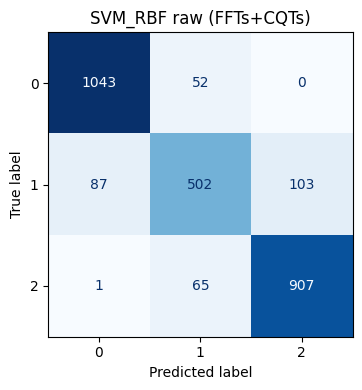

SVM_RBF raw (FFTs+CQTs) - Accuracy: 88.84%
Saved: confusion_matrices\svm_rbf_raw_ffts_cqts.png
  Training time: 0.01s


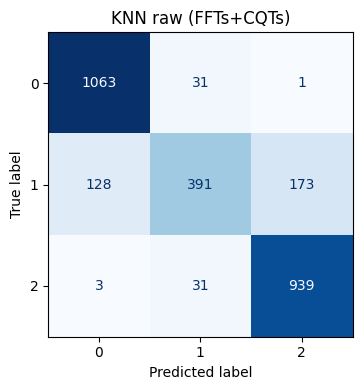

KNN raw (FFTs+CQTs) - Accuracy: 86.70%
Saved: confusion_matrices\knn_raw_ffts_cqts.png
  Training time: 10.65s


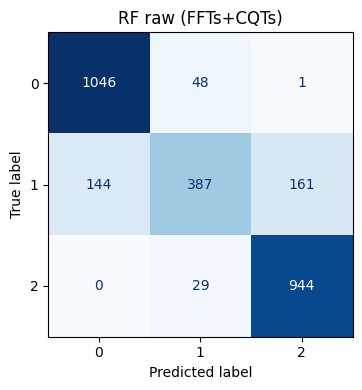

RF raw (FFTs+CQTs) - Accuracy: 86.12%
Saved: confusion_matrices\rf_raw_ffts_cqts.png
  Training time: 2.68s


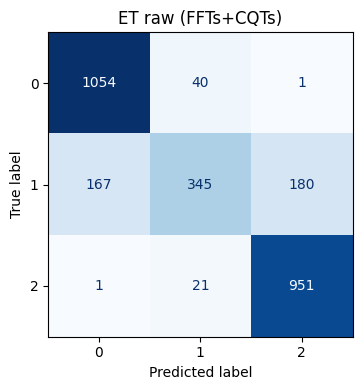

ET raw (FFTs+CQTs) - Accuracy: 85.14%
Saved: confusion_matrices\et_raw_ffts_cqts.png
  Training time: 5.74s


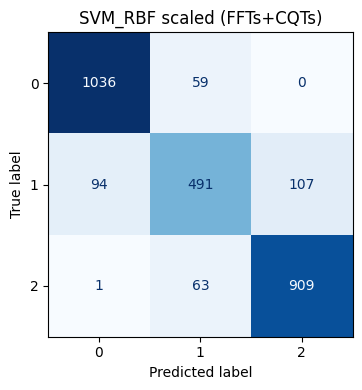

SVM_RBF scaled (FFTs+CQTs) - Accuracy: 88.26%
Saved: confusion_matrices\svm_rbf_scaled_ffts_cqts.png
  Training time: 0.01s


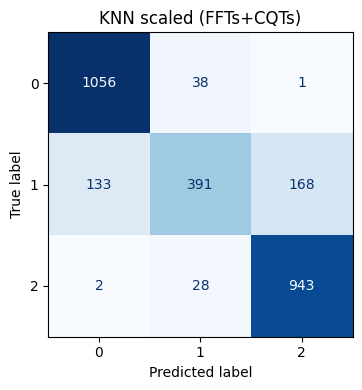

KNN scaled (FFTs+CQTs) - Accuracy: 86.59%
Saved: confusion_matrices\knn_scaled_ffts_cqts.png
  Training time: 10.65s


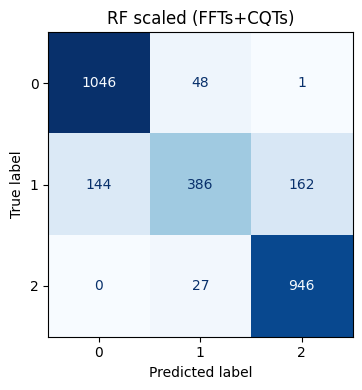

RF scaled (FFTs+CQTs) - Accuracy: 86.16%
Saved: confusion_matrices\rf_scaled_ffts_cqts.png
  Training time: 2.50s


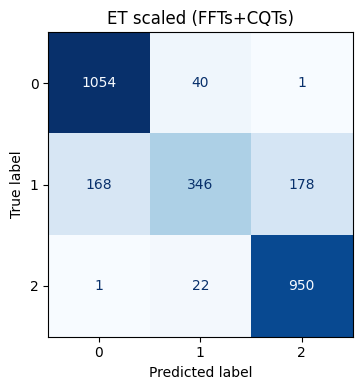

ET scaled (FFTs+CQTs) - Accuracy: 85.14%
Saved: confusion_matrices\et_scaled_ffts_cqts.png


In [32]:
print("=== FFTs + CQTs ===")

bayesian_svm = dict(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                    tol=0.0005319450186421158, cache_size=500, random_state=42)

models_ffts_cqts = {
    "SVM_RBF": SVC(**bayesian_svm),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
    "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42),
}

# Raw
for name, clf in models_ffts_cqts.items():
    train_and_evaluate(clf, ffts_cqts_train, ffts_train_labels2,
                       ffts_cqts_test, ffts_test_labels2,
                       f"{name} raw", "FFTs+CQTs")

# Scaled
for name, clf in models_ffts_cqts.items():
    # Re-create models (they were already fitted above)
    if name == "SVM_RBF": clf = SVC(**bayesian_svm)
    elif name == "KNN": clf = KNeighborsClassifier(n_neighbors=7, weights='distance', p=2)
    elif name == "RF": clf = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42)
    elif name == "ET": clf = ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
    train_and_evaluate(clf, ffts_cqts_train_scaled, ffts_train_labels2,
                       ffts_cqts_test_scaled, ffts_test_labels2,
                       f"{name} scaled", "FFTs+CQTs")

# 11. PCA (FFTs + CQTs)

In [33]:
# PCA on FFTs (130) and CQTs (80) separately, rs=42
pca_ffts = PCA(n_components=130, random_state=42)
pca_ffts_train = pca_ffts.fit_transform(ffts_train2)
pca_ffts_test  = pca_ffts.transform(ffts_test2)

pca_cqts = PCA(n_components=80, random_state=42)
pca_cqts_train = pca_cqts.fit_transform(cqts_train2)
pca_cqts_test  = pca_cqts.transform(cqts_test2)

pca_ffts_cqts_train = np.hstack((pca_ffts_train, pca_cqts_train))
pca_ffts_cqts_test  = np.hstack((pca_ffts_test,  pca_cqts_test))

scaler_pca_ffts_cqts = StandardScaler()
pca_ffts_cqts_train_scaled = scaler_pca_ffts_cqts.fit_transform(pca_ffts_cqts_train)
pca_ffts_cqts_test_scaled  = scaler_pca_ffts_cqts.transform(pca_ffts_cqts_test)

print(f"PCA(FFTs+CQTs) — Train: {pca_ffts_cqts_train.shape}, Test: {pca_ffts_cqts_test.shape}")

PCA(FFTs+CQTs) — Train: (11032, 210), Test: (2760, 210)


=== PCA (FFTs + CQTs) ===
  Training time: 3.43s


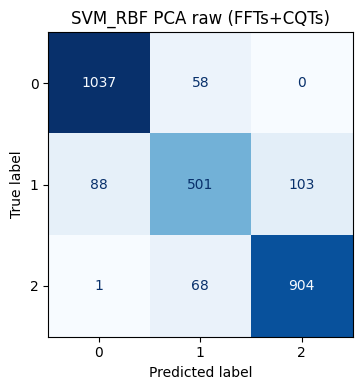

SVM_RBF PCA raw (FFTs+CQTs) - Accuracy: 88.48%
Saved: confusion_matrices\svm_rbf_pca_raw_ffts_cqts.png
  Training time: 0.00s


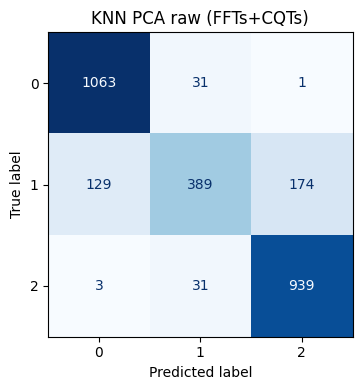

KNN PCA raw (FFTs+CQTs) - Accuracy: 86.63%
Saved: confusion_matrices\knn_pca_raw_ffts_cqts.png
  Training time: 9.13s


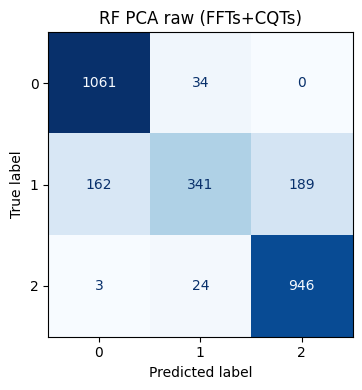

RF PCA raw (FFTs+CQTs) - Accuracy: 85.07%
Saved: confusion_matrices\rf_pca_raw_ffts_cqts.png
  Training time: 3.02s


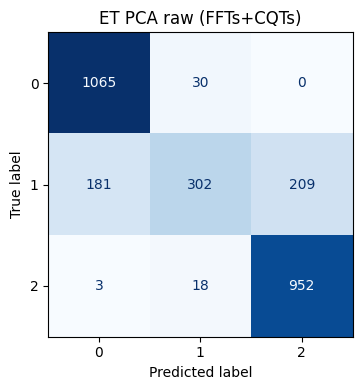

ET PCA raw (FFTs+CQTs) - Accuracy: 84.02%
Saved: confusion_matrices\et_pca_raw_ffts_cqts.png
  Training time: 10.90s


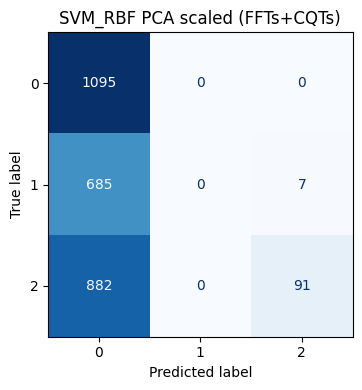

SVM_RBF PCA scaled (FFTs+CQTs) - Accuracy: 42.97%
Saved: confusion_matrices\svm_rbf_pca_scaled_ffts_cqts.png
  Training time: 0.01s


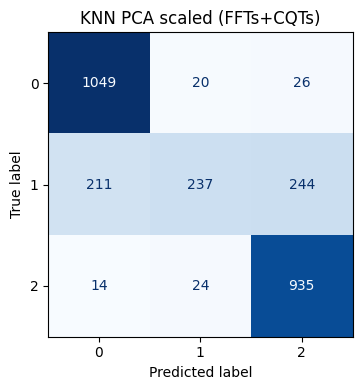

KNN PCA scaled (FFTs+CQTs) - Accuracy: 80.47%
Saved: confusion_matrices\knn_pca_scaled_ffts_cqts.png
  Training time: 9.42s


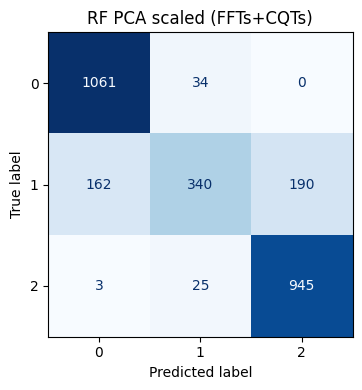

RF PCA scaled (FFTs+CQTs) - Accuracy: 85.00%
Saved: confusion_matrices\rf_pca_scaled_ffts_cqts.png
  Training time: 2.93s


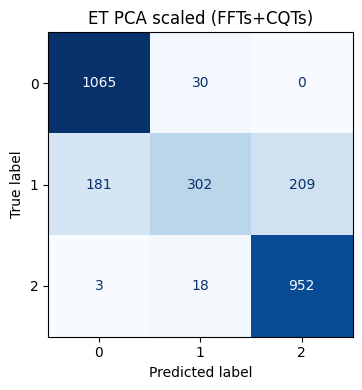

ET PCA scaled (FFTs+CQTs) - Accuracy: 84.02%
Saved: confusion_matrices\et_pca_scaled_ffts_cqts.png


In [34]:
print("=== PCA (FFTs + CQTs) ===")

bayesian_svm = dict(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                    tol=0.0005319450186421158, cache_size=500, random_state=42)

models_pca = {
    "SVM_RBF": SVC(**bayesian_svm),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
    "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42),
}

# PCA raw
for name, clf in models_pca.items():
    train_and_evaluate(clf, pca_ffts_cqts_train, ffts_train_labels2,
                       pca_ffts_cqts_test, ffts_test_labels2,
                       f"{name} PCA raw", "FFTs+CQTs")

# PCA scaled
for name, clf in models_pca.items():
    if name == "SVM_RBF": clf = SVC(**bayesian_svm)
    elif name == "KNN": clf = KNeighborsClassifier(n_neighbors=7, weights='distance', p=2)
    elif name == "RF": clf = RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42)
    elif name == "ET": clf = ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42)
    train_and_evaluate(clf, pca_ffts_cqts_train_scaled, ffts_train_labels2,
                       pca_ffts_cqts_test_scaled, ffts_test_labels2,
                       f"{name} PCA scaled", "FFTs+CQTs")

# 12. FFTs + CQT + STFT + PCA

In [35]:
# --- Combine PCA(FFTs+CQT) [246 dims from Sec 9] + PCA(STFT) [80] ---

# Re-load STFT features
stft_train2, _ = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024,
                                                   output_dir=output_dir, dataset_type='train')
stft_val2, _   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024,
                                                   output_dir=output_dir, dataset_type='val')
stft_test2, _  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024,
                                                   output_dir=output_dir, dataset_type='test')
stft_train2 = np.vstack((stft_train2, stft_val2))

# PCA on STFT: 80 components (random_state=3951)
pca_stft = PCA(n_components=80, random_state=3951)
pca_stft_train = pca_stft.fit_transform(stft_train2)
pca_stft_test  = pca_stft.transform(stft_test2)

# Combine: PCA(FFTs+CQT) [246] + PCA(STFT) [80] = 326
final_train = np.hstack((combined_train_pca, pca_stft_train))
final_test  = np.hstack((combined_test_pca,  pca_stft_test))

scaler_final = StandardScaler()
final_train_scaled = scaler_final.fit_transform(final_train)
final_test_scaled  = scaler_final.transform(final_test)

print(f"FFTs+CQT+STFT PCA — Train: {final_train.shape}, Test: {final_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQT+STFT PCA — Train: (11032, 326), Test: (2760, 326)


=== FFTs + CQT + STFT + PCA ===
  Training time: 0.02s


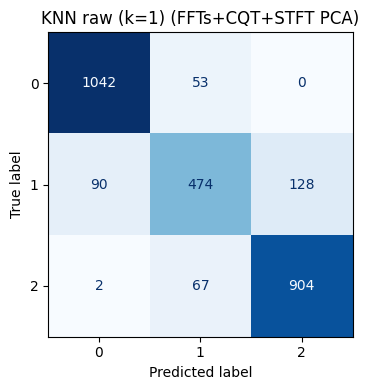

KNN raw (k=1) (FFTs+CQT+STFT PCA) - Accuracy: 87.68%
Saved: confusion_matrices\knn_raw_k=1_ffts_cqt_stft_pca.png
  Training time: 0.01s


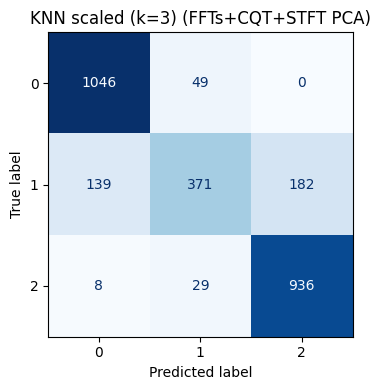

KNN scaled (k=3) (FFTs+CQT+STFT PCA) - Accuracy: 85.25%
Saved: confusion_matrices\knn_scaled_k=3_ffts_cqt_stft_pca.png
  Training time: 12.26s


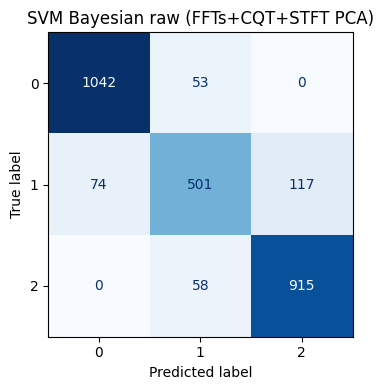

SVM Bayesian raw (FFTs+CQT+STFT PCA) - Accuracy: 89.06%
Saved: confusion_matrices\svm_bayesian_raw_ffts_cqt_stft_pca.png
  Training time: 23.91s


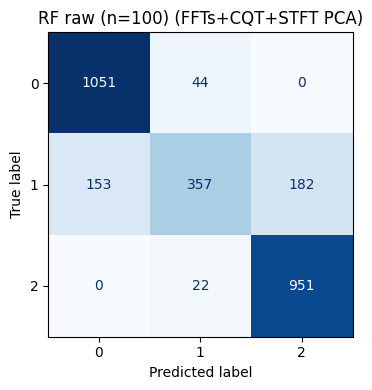

RF raw (n=100) (FFTs+CQT+STFT PCA) - Accuracy: 85.47%
Saved: confusion_matrices\rf_raw_n=100_ffts_cqt_stft_pca.png
  Training time: 8.11s


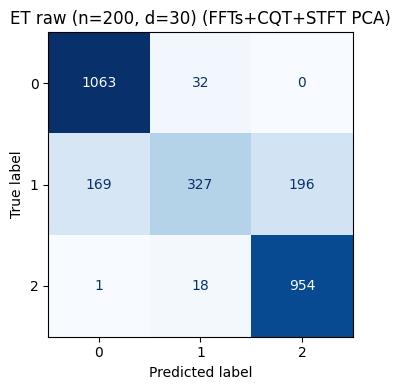

ET raw (n=200, d=30) (FFTs+CQT+STFT PCA) - Accuracy: 84.93%
Saved: confusion_matrices\et_raw_n=200_d=30_ffts_cqt_stft_pca.png


(0.8492753623188406,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

In [36]:
print("=== FFTs + CQT + STFT + PCA ===")

# KNN raw (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "KNN raw (k=1)", "FFTs+CQT+STFT PCA")

# KNN scaled (k=3)
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   final_train_scaled, combined_train_labels,
                   final_test_scaled,  combined_test_labels,
                   "KNN scaled (k=3)", "FFTs+CQT+STFT PCA")

# SVM Bayesian raw
train_and_evaluate(SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                       tol=0.0005319450186421158, cache_size=500, random_state=42),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "SVM Bayesian raw", "FFTs+CQT+STFT PCA")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "RF raw (n=100)", "FFTs+CQT+STFT PCA")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   final_train, combined_train_labels,
                   final_test,  combined_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+CQT+STFT PCA")

# 13. PCA (FFTs + CQTs + STFT) — No random_state

In [37]:
# --- Reload all features, apply PCA without random_state ---

print("=" * 60)
print("Loading all features for final PCA combination...")

# FFTs
r_ffts_train, r_ffts_labels = load_fft_features_from_directory(train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
r_ffts_val, _               = load_fft_features_from_directory(val_path,   NFFT=512, output_dir=output_dir, dataset_type='val')
r_ffts_test, r_ffts_test_labels = load_fft_features_from_directory(test_path, NFFT=512, output_dir=output_dir, dataset_type='test')
r_ffts_train = np.vstack((r_ffts_train, r_ffts_val))
r_ffts_labels = np.hstack((r_ffts_labels, _))

# CQTs
r_cqts_train, _ = load_cqts_features_from_directory(train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
r_cqts_val, _   = load_cqts_features_from_directory(val_path,   n_bins=84, output_dir=output_dir, dataset_type='val')
r_cqts_test, _  = load_cqts_features_from_directory(test_path,  n_bins=84, output_dir=output_dir, dataset_type='test')
r_cqts_train = np.vstack((r_cqts_train, r_cqts_val))

# STFT
r_stft_train, _ = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
r_stft_val, _   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
r_stft_test, _  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')
r_stft_train = np.vstack((r_stft_train, r_stft_val))

# PCA WITHOUT random_state
def apply_pca_no_rs(train_features, test_features, n_components):
    pca = PCA(n_components=n_components)
    return pca.fit_transform(train_features), pca.transform(test_features), pca

p_ffts_train, p_ffts_test, _ = apply_pca_no_rs(r_ffts_train, r_ffts_test, 130)
p_cqts_train, p_cqts_test, _ = apply_pca_no_rs(r_cqts_train, r_cqts_test, 80)
p_stft_train, p_stft_test, _ = apply_pca_no_rs(r_stft_train, r_stft_test, 80)

# Combine: 130 + 80 + 80 = 290
pca_all_train = np.hstack((p_ffts_train, p_cqts_train, p_stft_train))
pca_all_test  = np.hstack((p_ffts_test,  p_cqts_test,  p_stft_test))

print(f"PCA(FFTs+CQTs+STFT) — Train: {pca_all_train.shape}, Test: {pca_all_test.shape}")

Loading all features for final PCA combination...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
PCA(FFTs+CQTs+STFT) — Train: (11032, 290), Test: (2760, 290)


=== PCA (FFTs + CQTs + STFT) — 290 features ===
  Training time: 11.49s


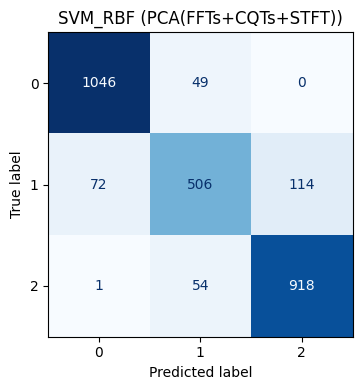

SVM_RBF (PCA(FFTs+CQTs+STFT)) - Accuracy: 89.49%
Saved: confusion_matrices\svm_rbf_pcaffts_cqts_stft.png
  Training time: 0.01s


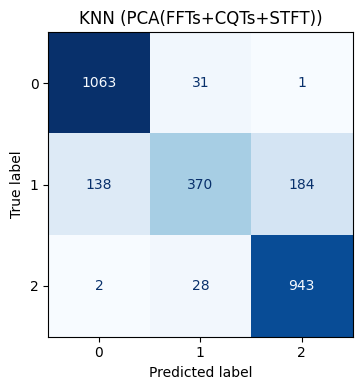

KNN (PCA(FFTs+CQTs+STFT)) - Accuracy: 86.09%
Saved: confusion_matrices\knn_pcaffts_cqts_stft.png
  Training time: 11.26s


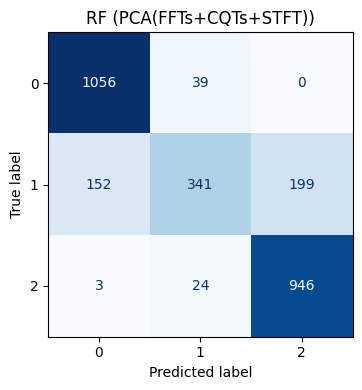

RF (PCA(FFTs+CQTs+STFT)) - Accuracy: 84.89%
Saved: confusion_matrices\rf_pcaffts_cqts_stft.png
  Training time: 3.03s


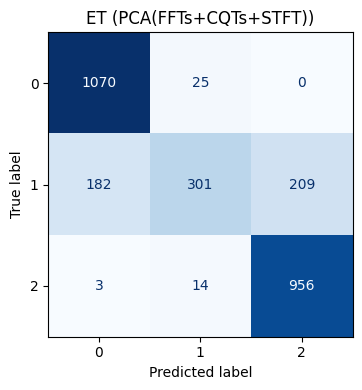

ET (PCA(FFTs+CQTs+STFT)) - Accuracy: 84.31%
Saved: confusion_matrices\et_pcaffts_cqts_stft.png


In [38]:
print("=== PCA (FFTs + CQTs + STFT) — 290 features ===")

bayesian_svm = dict(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                    tol=0.0005319450186421158, cache_size=500, random_state=42)

models_final = {
    "SVM_RBF": SVC(**bayesian_svm),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', p=2),
    "RF": RandomForestClassifier(n_estimators=400, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, n_jobs=-1, random_state=42),
}

for name, clf in models_final.items():
    train_and_evaluate(clf, pca_all_train, r_ffts_labels,
                       pca_all_test, r_ffts_test_labels,
                       name, "PCA(FFTs+CQTs+STFT)")

# 14. FFTs + CQTs + STFT (Raw & Scaled)

In [39]:
# --- Combine raw FFTs + CQTs + STFT (no PCA) ---

raw_all_train = np.hstack((r_ffts_train, r_cqts_train, r_stft_train))
raw_all_test  = np.hstack((r_ffts_test,  r_cqts_test,  r_stft_test))

scaler_raw_all = StandardScaler()
raw_all_train_scaled = scaler_raw_all.fit_transform(raw_all_train)
raw_all_test_scaled  = scaler_raw_all.transform(raw_all_test)

print(f"FFTs+CQTs+STFT raw — Train: {raw_all_train.shape}, Test: {raw_all_test.shape}")

FFTs+CQTs+STFT raw — Train: (11032, 2390), Test: (2760, 2390)


=== FFTs + CQTs + STFT (Raw & Scaled) ===
  Training time: 0.04s


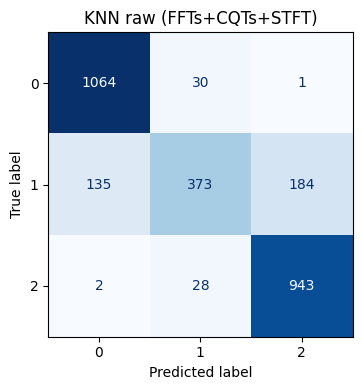

KNN raw (FFTs+CQTs+STFT) - Accuracy: 86.23%
Saved: confusion_matrices\knn_raw_ffts_cqts_stft.png
  Training time: 188.45s


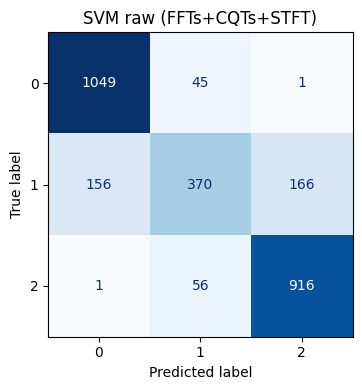

SVM raw (FFTs+CQTs+STFT) - Accuracy: 84.60%
Saved: confusion_matrices\svm_raw_ffts_cqts_stft.png
  Training time: 35.47s


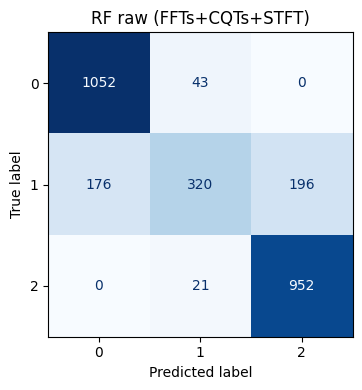

RF raw (FFTs+CQTs+STFT) - Accuracy: 84.20%
Saved: confusion_matrices\rf_raw_ffts_cqts_stft.png
  Training time: 16.31s


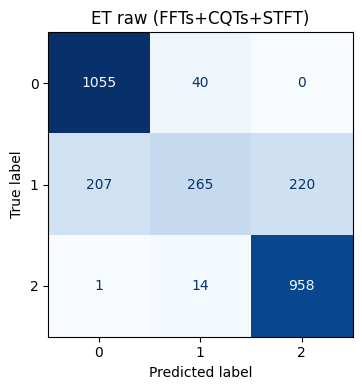

ET raw (FFTs+CQTs+STFT) - Accuracy: 82.54%
Saved: confusion_matrices\et_raw_ffts_cqts_stft.png
  Training time: 0.07s


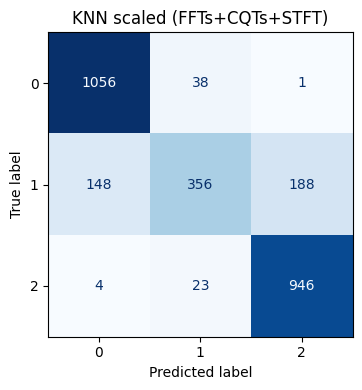

KNN scaled (FFTs+CQTs+STFT) - Accuracy: 85.43%
Saved: confusion_matrices\knn_scaled_ffts_cqts_stft.png
  Training time: 189.54s


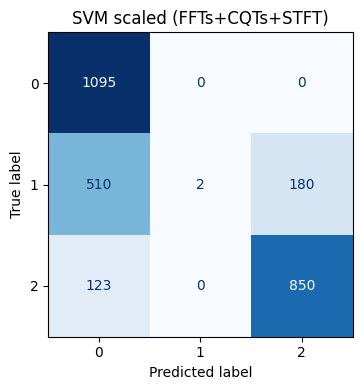

SVM scaled (FFTs+CQTs+STFT) - Accuracy: 70.54%
Saved: confusion_matrices\svm_scaled_ffts_cqts_stft.png
  Training time: 29.98s


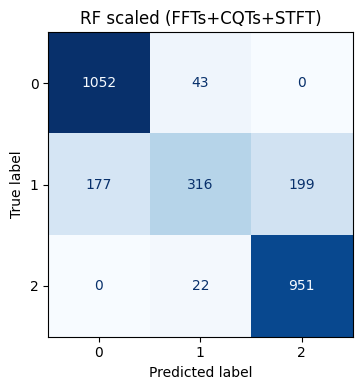

RF scaled (FFTs+CQTs+STFT) - Accuracy: 84.02%
Saved: confusion_matrices\rf_scaled_ffts_cqts_stft.png
  Training time: 14.32s


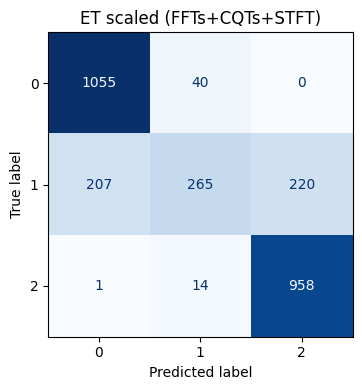

ET scaled (FFTs+CQTs+STFT) - Accuracy: 82.54%
Saved: confusion_matrices\et_scaled_ffts_cqts_stft.png


In [40]:
print("=== FFTs + CQTs + STFT (Raw & Scaled) ===")

bayesian_svm = dict(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                    tol=0.0005319450186421158, cache_size=500, random_state=42)

# Raw
for name, params in [("KNN", dict(n_neighbors=7, weights='distance', p=2)),
                     ("SVM", bayesian_svm),
                     ("RF", dict(n_estimators=400, n_jobs=-1, random_state=42)),
                     ("ET", dict(n_estimators=600, n_jobs=-1, random_state=42))]:
    if name == "KNN": clf = KNeighborsClassifier(**params)
    elif name == "SVM": clf = SVC(**params)
    elif name == "RF": clf = RandomForestClassifier(**params)
    elif name == "ET": clf = ExtraTreesClassifier(**params)
    train_and_evaluate(clf, raw_all_train, r_ffts_labels,
                       raw_all_test, r_ffts_test_labels,
                       f"{name} raw", "FFTs+CQTs+STFT")

# Scaled
for name, params in [("KNN", dict(n_neighbors=7, weights='distance', p=2)),
                     ("SVM", bayesian_svm),
                     ("RF", dict(n_estimators=400, n_jobs=-1, random_state=42)),
                     ("ET", dict(n_estimators=600, n_jobs=-1, random_state=42))]:
    if name == "KNN": clf = KNeighborsClassifier(**params)
    elif name == "SVM": clf = SVC(**params)
    elif name == "RF": clf = RandomForestClassifier(**params)
    elif name == "ET": clf = ExtraTreesClassifier(**params)
    train_and_evaluate(clf, raw_all_train_scaled, r_ffts_labels,
                       raw_all_test_scaled, r_ffts_test_labels,
                       f"{name} scaled", "FFTs+CQTs+STFT")

# 15. FFTs + CQT + STFT (Raw & Scaled)

In [41]:
# --- Combine raw FFTs + standalone CQT + STFT (no PCA) ---
# Uses CQT (not CQTs) from Section 7

raw_cqt_train = np.hstack((r_ffts_train, cqt_train, r_stft_train))
raw_cqt_test  = np.hstack((r_ffts_test,  cqt_test,  r_stft_test))

scaler_raw_cqt = StandardScaler()
raw_cqt_train_scaled = scaler_raw_cqt.fit_transform(raw_cqt_train)
raw_cqt_test_scaled  = scaler_raw_cqt.transform(raw_cqt_test)

print(f"FFTs+CQT+STFT raw — Train: {raw_cqt_train.shape}, Test: {raw_cqt_test.shape}")

FFTs+CQT+STFT raw — Train: (11032, 2390), Test: (2760, 2390)


=== FFTs + CQT + STFT (Raw & Scaled) ===
  Training time: 0.05s


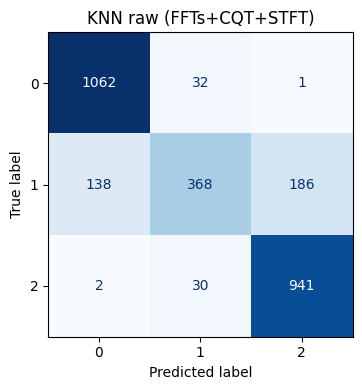

KNN raw (FFTs+CQT+STFT) - Accuracy: 85.91%
Saved: confusion_matrices\knn_raw_ffts_cqt_stft.png
  Training time: 186.69s


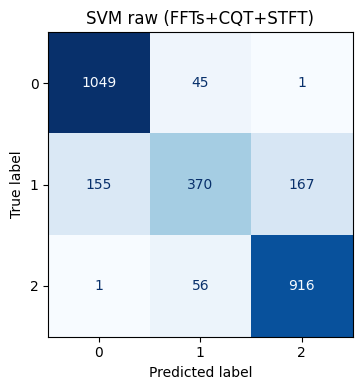

SVM raw (FFTs+CQT+STFT) - Accuracy: 84.60%
Saved: confusion_matrices\svm_raw_ffts_cqt_stft.png
  Training time: 36.35s


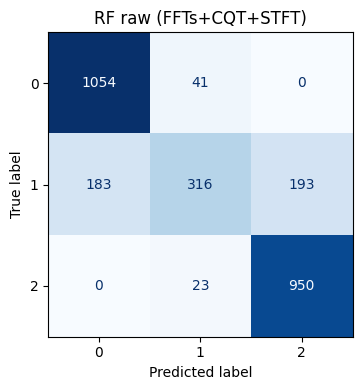

RF raw (FFTs+CQT+STFT) - Accuracy: 84.06%
Saved: confusion_matrices\rf_raw_ffts_cqt_stft.png
  Training time: 13.43s


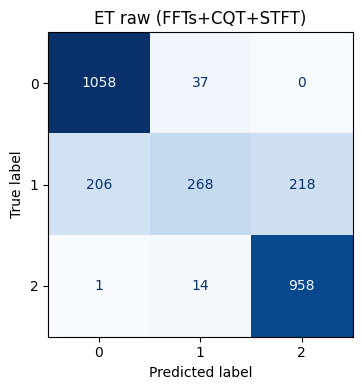

ET raw (FFTs+CQT+STFT) - Accuracy: 82.75%
Saved: confusion_matrices\et_raw_ffts_cqt_stft.png
  Training time: 0.06s


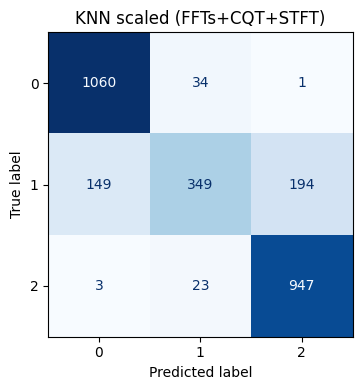

KNN scaled (FFTs+CQT+STFT) - Accuracy: 85.36%
Saved: confusion_matrices\knn_scaled_ffts_cqt_stft.png
  Training time: 179.46s


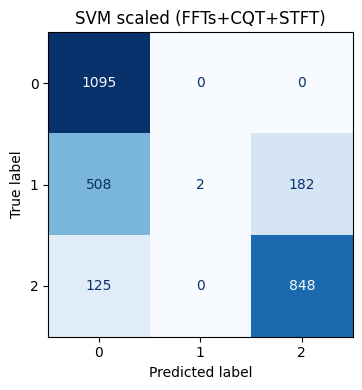

SVM scaled (FFTs+CQT+STFT) - Accuracy: 70.47%
Saved: confusion_matrices\svm_scaled_ffts_cqt_stft.png
  Training time: 35.04s


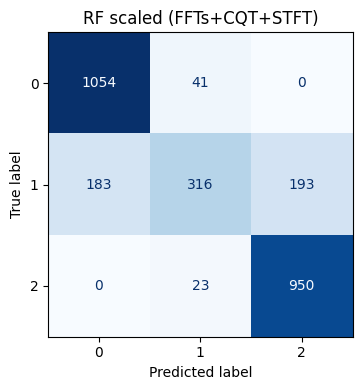

RF scaled (FFTs+CQT+STFT) - Accuracy: 84.06%
Saved: confusion_matrices\rf_scaled_ffts_cqt_stft.png
  Training time: 13.49s


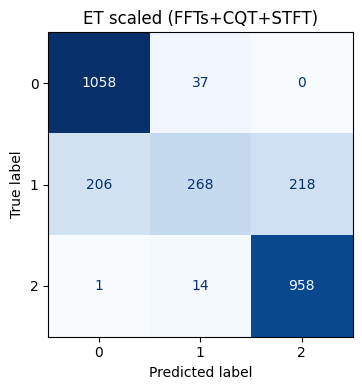

ET scaled (FFTs+CQT+STFT) - Accuracy: 82.75%
Saved: confusion_matrices\et_scaled_ffts_cqt_stft.png


In [42]:
print("=== FFTs + CQT + STFT (Raw & Scaled) ===")

bayesian_svm = dict(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                    tol=0.0005319450186421158, cache_size=500, random_state=42)

# Raw
for name, params in [("KNN", dict(n_neighbors=7, weights='distance', p=2)),
                     ("SVM", bayesian_svm),
                     ("RF", dict(n_estimators=400, n_jobs=-1, random_state=42)),
                     ("ET", dict(n_estimators=600, n_jobs=-1, random_state=42))]:
    if name == "KNN": clf = KNeighborsClassifier(**params)
    elif name == "SVM": clf = SVC(**params)
    elif name == "RF": clf = RandomForestClassifier(**params)
    elif name == "ET": clf = ExtraTreesClassifier(**params)
    train_and_evaluate(clf, raw_cqt_train, r_ffts_labels,
                       raw_cqt_test, r_ffts_test_labels,
                       f"{name} raw", "FFTs+CQT+STFT")

# Scaled
for name, params in [("KNN", dict(n_neighbors=7, weights='distance', p=2)),
                     ("SVM", bayesian_svm),
                     ("RF", dict(n_estimators=400, n_jobs=-1, random_state=42)),
                     ("ET", dict(n_estimators=600, n_jobs=-1, random_state=42))]:
    if name == "KNN": clf = KNeighborsClassifier(**params)
    elif name == "SVM": clf = SVC(**params)
    elif name == "RF": clf = RandomForestClassifier(**params)
    elif name == "ET": clf = ExtraTreesClassifier(**params)
    train_and_evaluate(clf, raw_cqt_train_scaled, r_ffts_labels,
                       raw_cqt_test_scaled, r_ffts_test_labels,
                       f"{name} scaled", "FFTs+CQT+STFT")

# Machine Learning Pipeline — Dataset 2 (NuHive/Kaggle)

In [43]:
import os
import time
import numpy as np
import librosa
import joblib
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.decomposition import PCA
import warnings
warnings.filterwarnings('ignore')

In [44]:
# ============ DATASET PATHS ============
DATASET_NAME = "Dataset 2 - NuHive/Kaggle"
BASE_PATH = r"D:\Queenless\archive\nuhive_processed"
FEATURE_DIR = r"D:\Queenless\kaggle_features"
LABELS = ['bee', 'nobee', 'noqueen']

train_path = os.path.join(BASE_PATH, 'train')
val_path   = os.path.join(BASE_PATH, 'val')
test_path  = os.path.join(BASE_PATH, 'test')
output_dir = FEATURE_DIR
os.makedirs(output_dir, exist_ok=True)

print(f"Dataset: {DATASET_NAME}")
print(f"Labels:  {LABELS}")

Dataset: Dataset 2 - NuHive/Kaggle
Labels:  ['bee', 'nobee', 'noqueen']


In [45]:
def train_and_evaluate(clf, X_train, y_train, X_test, y_test,
                       model_name="Model", feature_name="Feature"):
    """Train a classifier, predict on test set, print accuracy & time."""
    start = time.time()
    clf.fit(X_train, y_train)
    elapsed = time.time() - start
    preds = clf.predict(X_test)
    acc = accuracy_score(y_test, preds)
    print(f"  {model_name:30s} | Acc: {acc*100:.2f}% | Time: {elapsed:.2f}s")
    return acc, preds

# 1. FFT (Origin)

In [46]:
# --- FFT Origin: extract raw FFT magnitude (no pre-emphasis) ---
# Dataset2: n_fft=2048 (vs 512 for dataset1)

def extract_fft_features(file_path, n_fft=2048):
    """Load audio and compute raw FFT magnitude (positive freqs only)."""
    try:
        audio, sr = librosa.load(file_path, sr=None)
        fft = np.fft.fft(audio, n=n_fft)
        fft_magnitude = np.abs(fft[:n_fft // 2])  # positive frequencies
        return fft_magnitude
    except Exception as e:
        print(f"Error processing {file_path}: {e}")
        return None

def load_dataset_fft(base_path, labels):
    """Walk train/val/test splits, extract FFT features, encode labels."""
    splits = {}
    for split in ['train', 'val', 'test']:
        features, raw_labels = [], []
        for label in labels:
            folder = os.path.join(base_path, split, label)
            if not os.path.exists(folder):
                continue
            for fname in os.listdir(folder):
                if fname.endswith('.wav'):
                    feat = extract_fft_features(os.path.join(folder, fname), n_fft=2048)
                    if feat is not None:
                        features.append(feat)
                        raw_labels.append(label)
        splits[split] = (np.array(features), raw_labels)

    # Encode labels with a shared LabelEncoder
    le = LabelEncoder()
    all_raw = splits['train'][1] + splits['val'][1] + splits['test'][1]
    le.fit(all_raw)

    result = {}
    for split in ['train', 'val', 'test']:
        feats, raw = splits[split]
        result[split] = (feats, le.transform(raw))
        print(f"  {split}: {feats.shape}")
    return result

print("Loading FFT Origin features...")
fft_data = load_dataset_fft(BASE_PATH, LABELS)

Loading FFT Origin features...
  train: (9653, 1024)
  val: (1379, 1024)
  test: (2760, 1024)


In [47]:
# Merge train + val, scale
fft_train = np.vstack((fft_data['train'][0], fft_data['val'][0]))
fft_train_labels = np.hstack((fft_data['train'][1], fft_data['val'][1]))
fft_test = fft_data['test'][0]
fft_test_labels = fft_data['test'][1]

scaler_fft_origin = StandardScaler()
fft_train_scaled = scaler_fft_origin.fit_transform(fft_train)
fft_test_scaled  = scaler_fft_origin.transform(fft_test)

print(f"Train: {fft_train.shape}, Test: {fft_test.shape}")

Train: (11032, 1024), Test: (2760, 1024)


In [48]:
print("=== FFT Origin ===")

# KNN raw (k=19) — dataset2 uses k=19 (vs k=55 for dataset1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=19),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "KNN raw (k=19)", "FFT Origin")

# KNN scaled (k=19)
train_and_evaluate(KNeighborsClassifier(n_neighbors=19),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "KNN scaled (k=19)", "FFT Origin")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFT Origin")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_train_scaled, fft_train_labels, fft_test_scaled, fft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFT Origin")

# RF raw
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "RF raw (n=100)", "FFT Origin")

# ET raw (n=200, d=30) — dataset2: NO ET scaled (unlike dataset1)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   fft_train, fft_train_labels, fft_test, fft_test_labels,
                   "ET raw (n=200, d=30)", "FFT Origin")

=== FFT Origin ===
  KNN raw (k=19)                 | Acc: 70.58% | Time: 0.02s
  KNN scaled (k=19)              | Acc: 58.22% | Time: 0.02s
  SVM raw (C=100, γ=0.1)         | Acc: 61.56% | Time: 62.20s
  SVM scaled (C=100, γ=0.1)      | Acc: 43.04% | Time: 103.26s
  RF raw (n=100)                 | Acc: 74.13% | Time: 45.76s
  ET raw (n=200, d=30)           | Acc: 73.33% | Time: 20.36s


(0.7333333333333333, array([0, 0, 0, ..., 2, 2, 2]))

# 2. FFTs (Pre-emphasis + Framing + Windowing + FFT)

In [49]:
# --- Signal processing pipeline for FFTs ---
# NOTE: These implementations are DATASET-SPECIFIC.
#   - framing() uses np.zeros + np.concatenate + np.tile, and
#     pad_signal_length = (num_frames - 1) * frame_step + frame_length
#   - fft_frames() uses np.fft.rfft (NOT np.fft.fft + slice)
#   - log uses feature + 1e-8 (NOT np.maximum)

def pre_emphasis(signal_in, pre_emph=0.97):
    """Boost high frequencies with first-order high-pass filter."""
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing(signal_in, sample_rate, frame_size=0.025, frame_stride=0.01):
    """Split signal into overlapping frames using np.zeros/np.concatenate/np.tile."""
    frame_length = int(round(frame_size * sample_rate))
    frame_step   = int(round(frame_stride * sample_rate))
    signal_length = len(signal_in)

    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1

    # Dataset2-specific: (num_frames - 1) * frame_step + frame_length
    pad_signal_length = (num_frames - 1) * frame_step + frame_length
    z = np.zeros(pad_signal_length - signal_length)
    pad_signal = np.concatenate([signal_in, z])

    indices = (np.tile(np.arange(0, frame_length), (num_frames, 1))
               + np.tile(np.arange(0, num_frames * frame_step, frame_step),
                         (frame_length, 1)).T)
    frames = pad_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing(frames):
    """Apply Hamming window to each frame."""
    frame_length = frames.shape[1]
    return frames * np.hamming(frame_length)

def fft_frames(frames, NFFT=512):
    """Compute FFT magnitude per frame — uses np.fft.rfft (not fft+slice)."""
    return np.absolute(np.fft.rfft(frames, NFFT))

In [50]:
def compute_fft_features(signal_in, sample_rate, frame_size=0.025,
                         frame_stride=0.01, NFFT=512, apply_log=True):
    """Full pipeline: pre-emphasis → framing → windowing → FFT → mean."""
    emphasized = pre_emphasis(signal_in)
    frames = framing(emphasized, sample_rate, frame_size, frame_stride)
    windowed = windowing(frames)
    mag = fft_frames(windowed, NFFT)
    feature = np.mean(mag, axis=0)          # average across frames
    if apply_log:
        feature = np.log(feature + 1e-8)    # Dataset2: addition (not np.maximum)
    return feature

def load_fft_features_from_directory(directory, sample_rate=22050, NFFT=512,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached FFTs features (pkl prefix: fft3_)."""
    feat_file  = os.path.join(output_dir, f'fft3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'fft3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_fft_features(sig, sr, NFFT=NFFT))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [51]:
# Load FFTs features from each split
ffts_train, ffts_train_labels = load_fft_features_from_directory(train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
ffts_val,   ffts_val_labels   = load_fft_features_from_directory(val_path,   NFFT=512, output_dir=output_dir, dataset_type='val')
ffts_test,  ffts_test_labels  = load_fft_features_from_directory(test_path,  NFFT=512, output_dir=output_dir, dataset_type='test')

# Merge train + val
ffts_train = np.vstack((ffts_train, ffts_val))
ffts_train_labels = np.hstack((ffts_train_labels, ffts_val_labels))

# Scale
scaler_ffts = StandardScaler()
ffts_train_scaled = scaler_ffts.fit_transform(ffts_train)
ffts_test_scaled  = scaler_ffts.transform(ffts_test)

print(f"FFTs — Train: {ffts_train.shape}, Test: {ffts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs — Train: (11032, 257), Test: (2760, 257)


In [52]:
print("=== FFTs ===")

# KNN raw (k=5) — dataset2 uses k=5
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "KNN raw (k=5)", "FFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_train_scaled, ffts_train_labels, ffts_test_scaled, ffts_test_labels,
                   "KNN scaled (k=5)", "FFTs")

# SVM raw (C=100, γ=0.1) — dataset2: raw only (no SVM scaled)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "RF raw (n=100)", "FFTs")

# ET raw (n=200, d=30) — dataset2: NO ET scaled
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   ffts_train, ffts_train_labels, ffts_test, ffts_test_labels,
                   "ET raw (n=200, d=30)", "FFTs")

=== FFTs ===
  KNN raw (k=5)                  | Acc: 86.52% | Time: 0.01s
  KNN scaled (k=5)               | Acc: 85.18% | Time: 0.01s
  SVM raw (C=100, γ=0.1)         | Acc: 87.72% | Time: 4.92s
  RF raw (n=100)                 | Acc: 84.38% | Time: 19.00s
  ET raw (n=200, d=30)           | Acc: 83.84% | Time: 7.05s


(0.8384057971014492,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 3. STFT

In [53]:
# --- STFT: librosa-based short-time Fourier transform ---

def compute_stft_features(signal_in, sample_rate, n_fft=2048, hop_length=512,
                          apply_log=True):
    """Compute STFT magnitude, average over time axis."""
    stft_matrix = np.abs(librosa.stft(signal_in, n_fft=n_fft, hop_length=hop_length))
    if apply_log:
        stft_matrix = np.log(stft_matrix + 1e-8)
    return np.mean(stft_matrix, axis=1)   # → shape (n_fft//2+1,)

def load_stft_features_from_directory(directory, sample_rate=22050,
                                      n_fft=2048, hop_length=512,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached STFT features (pkl prefix: stft2_)."""
    feat_file  = os.path.join(output_dir, f'stft2_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stft2_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stft_features(sig, sr, n_fft=n_fft,
                                                  hop_length=hop_length))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [54]:
# Load STFT features (n_fft=4096, hop_length=1024)
stft_train, stft_train_labels = load_stft_features_from_directory(train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
stft_val,   stft_val_labels   = load_stft_features_from_directory(val_path,   n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
stft_test,  stft_test_labels  = load_stft_features_from_directory(test_path,  n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')

stft_train = np.vstack((stft_train, stft_val))
stft_train_labels = np.hstack((stft_train_labels, stft_val_labels))

scaler_stft = StandardScaler()
stft_train_scaled = scaler_stft.fit_transform(stft_train)
stft_test_scaled  = scaler_stft.transform(stft_test)

print(f"STFT — Train: {stft_train.shape}, Test: {stft_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFT — Train: (11032, 2049), Test: (2760, 2049)


In [55]:
print("=== STFT ===")

# KNN raw (k=25) — dataset2 uses k=25 (vs k=3 for dataset1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=25),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "KNN raw (k=25)", "STFT")

# KNN scaled (k=25)
train_and_evaluate(KNeighborsClassifier(n_neighbors=25),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "KNN scaled (k=25)", "STFT")

# SVM raw (C=10, γ=scale)
train_and_evaluate(SVC(C=10, kernel='rbf', gamma='scale', random_state=42),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "SVM raw (C=10, γ=scale)", "STFT")

# SVM scaled (C=10, γ=scale)
train_and_evaluate(SVC(C=10, kernel='rbf', gamma='scale', random_state=42),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "SVM scaled (C=10, γ=scale)", "STFT")

# RF raw (n=100) — dataset2 HAS RF on STFT (dataset1 does not)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   stft_train, stft_train_labels, stft_test, stft_test_labels,
                   "RF raw (n=100)", "STFT")

# ET scaled (n=100) — dataset2 HAS ET on STFT (dataset1 does not), uses n=100
train_and_evaluate(ExtraTreesClassifier(n_estimators=100, random_state=42),
                   stft_train_scaled, stft_train_labels, stft_test_scaled, stft_test_labels,
                   "ET scaled (n=100)", "STFT")

=== STFT ===
  KNN raw (k=25)                 | Acc: 83.12% | Time: 0.04s
  KNN scaled (k=25)              | Acc: 82.14% | Time: 0.03s
  SVM raw (C=10, γ=scale)        | Acc: 81.85% | Time: 45.52s
  SVM scaled (C=10, γ=scale)     | Acc: 84.75% | Time: 43.14s
  RF raw (n=100)                 | Acc: 82.79% | Time: 61.89s
  ET scaled (n=100)              | Acc: 81.67% | Time: 13.44s


(0.8166666666666667,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 4. FFTs + STFT

In [56]:
# --- FFTs + STFT: concat raw → scale TOGETHER ---
# This is DATASET-SPECIFIC: Dataset2 scales the combined features,
# whereas Dataset1 scales each type separately then concatenates.

# Verify label consistency
if np.array_equal(ffts_train_labels, stft_train_labels) and np.array_equal(ffts_test_labels, stft_test_labels):
    print("✓ Labels are consistent between FFTs and STFT")
    fft_stft_train_labels = ffts_train_labels
    fft_stft_test_labels  = ffts_test_labels
else:
    print("⚠ Warning: Labels mismatch, using FFTs labels")
    fft_stft_train_labels = ffts_train_labels
    fft_stft_test_labels  = ffts_test_labels

# Raw concatenation
fft_stft_train_raw = np.hstack((ffts_train, stft_train))
fft_stft_test_raw  = np.hstack((ffts_test,  stft_test))

# Scale the combined features together
scaler_fft_stft = StandardScaler()
fft_stft_train_scaled = scaler_fft_stft.fit_transform(fft_stft_train_raw)
fft_stft_test_scaled  = scaler_fft_stft.transform(fft_stft_test_raw)

print(f"FFTs+STFT raw    — Train: {fft_stft_train_raw.shape}")
print(f"FFTs+STFT scaled — Train: {fft_stft_train_scaled.shape}")

✓ Labels are consistent between FFTs and STFT
FFTs+STFT raw    — Train: (11032, 2306)
FFTs+STFT scaled — Train: (11032, 2306)


In [57]:
print("=== FFTs + STFT ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "KNN raw (k=5)", "FFTs+STFT")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "KNN scaled (k=5)", "FFTs+STFT")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFT")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   fft_stft_train_scaled, fft_stft_train_labels,
                   fft_stft_test_scaled,  fft_stft_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFT")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "RF raw (n=100)", "FFTs+STFT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   fft_stft_train_raw, fft_stft_train_labels,
                   fft_stft_test_raw,  fft_stft_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+STFT")

=== FFTs + STFT ===
  KNN raw (k=5)                  | Acc: 86.12% | Time: 0.05s
  KNN scaled (k=5)               | Acc: 84.42% | Time: 0.06s
  SVM raw (C=100, γ=0.1)         | Acc: 41.30% | Time: 251.47s
  SVM scaled (C=100, γ=0.1)      | Acc: 39.67% | Time: 252.26s
  RF raw (n=100)                 | Acc: 83.30% | Time: 58.82s
  ET raw (n=200, d=30)           | Acc: 82.25% | Time: 22.84s


(0.822463768115942,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 5. STFTs (Pre-emphasis + STFT per frame)

In [58]:
# --- STFTs: Pre-emphasis → Framing → Windowing → STFT per frame ---
# Dataset2 uses INLINE implementation: all operations inside compute_stfts_features.
# (pre_emphasis, framing, windowing are redefined but NOT called by compute_stfts_features)

def compute_stfts_features(signal_in, sample_rate, frame_size=0.025,
                           frame_stride=0.01, n_fft=2048, apply_log=True):
    """Inline pre-emphasis → framing → windowing → STFT per frame → average."""
    # Pre-emphasis (inline)
    emphasized = np.append(signal_in[0], signal_in[1:] - 0.97 * signal_in[:-1])

    # Framing (inline)
    frame_length = int(round(frame_size * sample_rate))
    frame_step   = int(round(frame_stride * sample_rate))
    signal_length = len(emphasized)

    num_frames = int(np.ceil(np.abs(signal_length - frame_length) / frame_step)) + 1
    pad_signal_length = num_frames * frame_step + frame_length
    pad_signal = np.pad(emphasized, (0, pad_signal_length - signal_length), mode='constant')

    indices = np.arange(0, frame_length) + np.arange(0, num_frames * frame_step, frame_step)[:, None]
    frames = pad_signal[indices.astype(np.int32)]

    # Windowing (inline)
    frames *= np.hamming(frames.shape[1])

    # STFT per frame: take first time column of each frame's STFT
    mag_frames = []
    for frame in frames:
        stft = np.abs(librosa.stft(frame, n_fft=n_fft))
        mag_frames.append(stft[:, 0])

    mag_frames = np.array(mag_frames)
    feature = np.mean(mag_frames, axis=0)

    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))
    return feature

def load_stfts_features_from_directory(directory, sample_rate=22050, n_fft=2048,
                                       frame_size=0.025, frame_stride=0.01,
                                       output_dir=None, dataset_type='train'):
    """Extract or load cached STFTs features (pkl prefix: stfts3_)."""
    feat_file  = os.path.join(output_dir, f'stfts3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'stfts3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            print(f"  Warning: missing folder {folder}")
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_stfts_features(sig, sr, frame_size=frame_size,
                                                   frame_stride=frame_stride, n_fft=n_fft))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [59]:
stfts_train, stfts_train_labels = load_stfts_features_from_directory(train_path, n_fft=2048, output_dir=output_dir, dataset_type='train')
stfts_val,   stfts_val_labels   = load_stfts_features_from_directory(val_path,   n_fft=2048, output_dir=output_dir, dataset_type='val')
stfts_test,  stfts_test_labels  = load_stfts_features_from_directory(test_path,  n_fft=2048, output_dir=output_dir, dataset_type='test')

stfts_train = np.vstack((stfts_train, stfts_val))
stfts_train_labels = np.hstack((stfts_train_labels, stfts_val_labels))

scaler_stfts = StandardScaler()
stfts_train_scaled = scaler_stfts.fit_transform(stfts_train)
stfts_test_scaled  = scaler_stfts.transform(stfts_test)

print(f"STFTs — Train: {stfts_train.shape}, Test: {stfts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
STFTs — Train: (11032, 1025), Test: (2760, 1025)


In [60]:
print("=== STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "KNN raw (k=5)", "STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   stfts_train_scaled, stfts_train_labels, stfts_test_scaled, stfts_test_labels,
                   "KNN scaled (k=5)", "STFTs")

# SVM raw (C=80, γ=0.08) — dataset2-specific SVM params
train_and_evaluate(SVC(C=80, kernel='rbf', gamma=0.08, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "SVM raw (C=80, γ=0.08)", "STFTs")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "RF raw (n=100)", "STFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   stfts_train, stfts_train_labels, stfts_test, stfts_test_labels,
                   "ET raw (n=200, d=30)", "STFTs")

=== STFTs ===
  KNN raw (k=5)                  | Acc: 86.81% | Time: 0.02s
  KNN scaled (k=5)               | Acc: 85.00% | Time: 0.02s
  SVM raw (C=80, γ=0.08)         | Acc: 87.86% | Time: 30.54s
  RF raw (n=100)                 | Acc: 85.51% | Time: 34.04s
  ET raw (n=200, d=30)           | Acc: 84.64% | Time: 12.65s


(0.8463768115942029,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 6. FFTs + STFTs

In [61]:
# --- Combine FFTs + STFTs ---
ffts_stfts_train = np.hstack((ffts_train, stfts_train))
ffts_stfts_test  = np.hstack((ffts_test,  stfts_test))

scaler_ffts_stfts = StandardScaler()
ffts_stfts_train_scaled = scaler_ffts_stfts.fit_transform(ffts_stfts_train)
ffts_stfts_test_scaled  = scaler_ffts_stfts.transform(ffts_stfts_test)

# Use ffts labels (both come from same audio files)
ffts_stfts_labels_train = ffts_train_labels
ffts_stfts_labels_test  = ffts_test_labels

print(f"FFTs+STFTs — Train: {ffts_stfts_train.shape}, Test: {ffts_stfts_test.shape}")

FFTs+STFTs — Train: (11032, 1282), Test: (2760, 1282)


In [62]:
print("=== FFTs + STFTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "KNN raw (k=5)", "FFTs+STFTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "KNN scaled (k=5)", "FFTs+STFTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "SVM raw (C=100, γ=0.1)", "FFTs+STFTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   ffts_stfts_train_scaled, ffts_stfts_labels_train,
                   ffts_stfts_test_scaled,  ffts_stfts_labels_test,
                   "SVM scaled (C=100, γ=0.1)", "FFTs+STFTs")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "RF raw (n=100)", "FFTs+STFTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   ffts_stfts_train, ffts_stfts_labels_train,
                   ffts_stfts_test,  ffts_stfts_labels_test,
                   "ET raw (n=200, d=30)", "FFTs+STFTs")

=== FFTs + STFTs ===


  KNN raw (k=5)                  | Acc: 86.67% | Time: 0.03s
  KNN scaled (k=5)               | Acc: 84.78% | Time: 0.04s
  SVM raw (C=100, γ=0.1)         | Acc: 87.43% | Time: 55.14s
  SVM scaled (C=100, γ=0.1)      | Acc: 85.76% | Time: 67.05s
  RF raw (n=100)                 | Acc: 85.62% | Time: 38.07s
  ET raw (n=200, d=30)           | Acc: 84.93% | Time: 14.20s


(0.8492753623188406,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 7. CQT

In [63]:
# --- CQT: Constant-Q Transform (no pre-emphasis) ---

def compute_cqt_features(signal_in, sample_rate, hop_length=512, fmin=None,
                         n_bins=84, bins_per_octave=12, apply_log=True):
    """Compute CQT magnitude → log → average over time → shape (n_bins,)."""
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    if apply_log:
        cqt_matrix = np.log(cqt_matrix + 1e-8)
    return np.mean(cqt_matrix, axis=1)

def load_cqt_features_from_directory(directory, sample_rate=22050, hop_length=512,
                                     fmin=None, n_bins=84, bins_per_octave=12,
                                     output_dir=None, dataset_type='train'):
    """Extract or load cached CQT features (pkl prefix: cqt_)."""
    feat_file  = os.path.join(output_dir, f'cqt_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqt_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            continue
        for fname in os.listdir(folder):
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqt_features(sig, sr, hop_length=hop_length,
                                                 fmin=fmin, n_bins=n_bins,
                                                 bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [64]:
cqt_train, cqt_train_labels = load_cqt_features_from_directory(train_path, hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='train')
cqt_val,   cqt_val_labels   = load_cqt_features_from_directory(val_path,   hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='val')
cqt_test,  cqt_test_labels  = load_cqt_features_from_directory(test_path,  hop_length=512, n_bins=84, output_dir=output_dir, dataset_type='test')

cqt_train = np.vstack((cqt_train, cqt_val))
cqt_train_labels = np.hstack((cqt_train_labels, cqt_val_labels))

scaler_cqt = StandardScaler()
cqt_train_scaled = scaler_cqt.fit_transform(cqt_train)
cqt_test_scaled  = scaler_cqt.transform(cqt_test)

print(f"CQT — Train: {cqt_train.shape}, Test: {cqt_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQT — Train: (11032, 84), Test: (2760, 84)


In [65]:
print("=== CQT ===")

# KNN scaled (k=1) — dataset2 uses k=1 scaled (same as dataset1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "KNN scaled (k=1)", "CQT")

# SVM raw (C=100, γ=auto) — dataset2 trains SVM on raw TOO (dataset1: scaled only)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma='auto', random_state=42),
                   cqt_train, cqt_train_labels, cqt_test, cqt_test_labels,
                   "SVM raw (C=100, γ=auto)", "CQT")

# SVM scaled (C=100, γ=auto)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma='auto', random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "SVM scaled (C=100, γ=auto)", "CQT")

# LR scaled (C=1, iter=500)
train_and_evaluate(LogisticRegression(C=1.0, max_iter=500, solver='lbfgs', random_state=None),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "LR scaled (C=1, iter=500)", "CQT")

# RF raw (bootstrap=False)
train_and_evaluate(RandomForestClassifier(n_estimators=100, bootstrap=False, random_state=42),
                   cqt_train, cqt_train_labels, cqt_test, cqt_test_labels,
                   "RF raw (n=100, no bootstrap)", "CQT")

# ET scaled (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   cqt_train_scaled, cqt_train_labels, cqt_test_scaled, cqt_test_labels,
                   "ET scaled (n=200, d=30)", "CQT")

=== CQT ===
  KNN scaled (k=1)               | Acc: 85.54% | Time: 0.00s
  SVM raw (C=100, γ=auto)        | Acc: 85.29% | Time: 2.54s
  SVM scaled (C=100, γ=auto)     | Acc: 85.51% | Time: 2.50s
  LR scaled (C=1, iter=500)      | Acc: 74.71% | Time: 0.61s
  RF raw (n=100, no bootstrap)   | Acc: 86.34% | Time: 15.89s
  ET scaled (n=200, d=30)        | Acc: 85.04% | Time: 3.45s


(0.8503623188405797,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 8. CQTs (Pre-emphasis + CQT)

In [66]:
# --- CQTs: Pre-emphasis + CQT ---
# (pre_emphasis already defined above)

def compute_cqts_features(signal_in, sample_rate, frame_size=0.025,
                          frame_stride=0.01, fmin=None, n_bins=84,
                          bins_per_octave=12, apply_log=True):
    """Pre-emphasis → CQT on full signal → average over time."""
    emphasized = pre_emphasis(signal_in)
    cqt_matrix = np.abs(librosa.cqt(emphasized, sr=sample_rate,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave,
                                    hop_length=512))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(np.maximum(feature, 1e-8))
    return feature

def load_cqts_features_from_directory(directory, sample_rate=22050,
                                      frame_size=0.025, frame_stride=0.01,
                                      fmin=None, n_bins=84, bins_per_octave=12,
                                      output_dir=None, dataset_type='train'):
    """Extract or load cached CQTs features (pkl prefix: cqts3_)."""
    feat_file  = os.path.join(output_dir, f'cqts3_features_{dataset_type}.pkl')
    label_file = os.path.join(output_dir, f'cqts3_labels_{dataset_type}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.isdir(folder):
            print(f"  Warning: missing folder {folder}")
            continue
        for fname in os.listdir(folder):
            if not fname.lower().endswith('.wav'):
                continue
            fpath = os.path.join(folder, fname)
            sig, sr = librosa.load(fpath, sr=sample_rate)
            features.append(compute_cqts_features(sig, sr, frame_size=frame_size,
                                                  frame_stride=frame_stride, fmin=fmin,
                                                  n_bins=n_bins, bins_per_octave=bins_per_octave))
            labels.append(label)
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s")
    return features, labels

In [67]:
cqts_train, cqts_train_labels = load_cqts_features_from_directory(train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
cqts_val,   cqts_val_labels   = load_cqts_features_from_directory(val_path,   n_bins=84, output_dir=output_dir, dataset_type='val')
cqts_test,  cqts_test_labels  = load_cqts_features_from_directory(test_path,  n_bins=84, output_dir=output_dir, dataset_type='test')

cqts_train = np.vstack((cqts_train, cqts_val))
cqts_train_labels = np.hstack((cqts_train_labels, cqts_val_labels))

scaler_cqts = StandardScaler()
cqts_train_scaled = scaler_cqts.fit_transform(cqts_train)
cqts_test_scaled  = scaler_cqts.transform(cqts_test)

print(f"CQTs — Train: {cqts_train.shape}, Test: {cqts_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
CQTs — Train: (11032, 84), Test: (2760, 84)


In [68]:
print("=== CQTs ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "KNN raw (k=5)", "CQTs")

# KNN scaled (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "KNN scaled (k=5)", "CQTs")

# SVM raw (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "SVM raw (C=100, γ=0.1)", "CQTs")

# SVM scaled (C=100, γ=0.1)
train_and_evaluate(SVC(C=100, kernel='rbf', gamma=0.1, random_state=42),
                   cqts_train_scaled, cqts_train_labels, cqts_test_scaled, cqts_test_labels,
                   "SVM scaled (C=100, γ=0.1)", "CQTs")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "RF raw (n=100)", "CQTs")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   cqts_train, cqts_train_labels, cqts_test, cqts_test_labels,
                   "ET raw (n=200, d=30)", "CQTs")

=== CQTs ===
  KNN raw (k=5)                  | Acc: 86.52% | Time: 0.00s
  KNN scaled (k=5)               | Acc: 85.80% | Time: 0.00s
  SVM raw (C=100, γ=0.1)         | Acc: 85.76% | Time: 2.42s
  SVM scaled (C=100, γ=0.1)      | Acc: 86.01% | Time: 2.43s
  RF raw (n=100)                 | Acc: 85.58% | Time: 9.83s
  ET raw (n=200, d=30)           | Acc: 85.94% | Time: 3.30s


(0.8594202898550725,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 9. FFTs + CQT (Combined Feature Extraction)

In [69]:
# --- FFTs+CQT: DIFFERENT signal processing from Section 2 ---
# Dataset2 combined pipeline differences:
#   - framing: configurable hop_length/overlap, different pad formula
#   - windowing: Bartlett window (not Hamming)
#   - fft_frames: np.fft.rfft (same as Section 2 for dataset2)
#   - log: feature + 1e-8
#   - NFFT=2048 → feature dim = 1025 (FFT) + 96 (CQT) = 1121

def pre_emphasis_combined(signal_in, pre_emph=0.97):
    """Pre-emphasis filter (same as other sections)."""
    return np.append(signal_in[0], signal_in[1:] - pre_emph * signal_in[:-1])

def framing_combined(signal_in, sample_rate, frame_size=0.025, hop_length=256, overlap=0.6):
    """Framing with configurable hop_length/overlap and Bartlett-compatible padding."""
    # Determine frame length in samples
    if frame_size <= 1:
        frame_length = int(round(frame_size * sample_rate))
    else:
        frame_length = int(frame_size)

    # Determine hop (step) in samples
    if hop_length is None:
        frame_step = int(frame_length * (1 - overlap))
    elif hop_length <= 1:
        frame_step = int(round(hop_length * sample_rate))
    else:
        frame_step = int(hop_length)
    frame_step = max(1, frame_step)

    signal_length = len(signal_in)
    num_frames = int(np.ceil((signal_length - frame_length) / frame_step)) + 1

    pad_signal_length = (num_frames - 1) * frame_step + frame_length
    pad_zeros = np.zeros(pad_signal_length - signal_length)
    padded_signal = np.concatenate([signal_in, pad_zeros])

    indices = (np.tile(np.arange(0, frame_length), (num_frames, 1))
               + np.tile(np.arange(0, num_frames * frame_step, frame_step),
                         (frame_length, 1)).T)
    indices = np.minimum(indices, len(padded_signal) - 1)
    frames = padded_signal[indices.astype(np.int32, copy=False)]
    return frames

def windowing_combined(frames, window_type='bartlett'):
    """Apply configurable window (default: Bartlett for dataset2)."""
    frame_length = frames.shape[1]
    if window_type == 'hamming':
        window = np.hamming(frame_length)
    elif window_type == 'hanning':
        window = np.hanning(frame_length)
    elif window_type == 'blackman':
        window = np.blackman(frame_length)
    elif window_type == 'bartlett':
        window = np.bartlett(frame_length)
    else:
        window = np.hamming(frame_length)
    return frames * window

def fft_frames_combined(frames, NFFT=512):
    """FFT using np.fft.rfft."""
    return np.absolute(np.fft.rfft(frames, NFFT))

def compute_fft_features_combined(signal_in, sample_rate, frame_size=0.025,
                                  hop_length=256, overlap=0.6, NFFT=512,
                                  apply_log=True, window_type='bartlett',
                                  normalize=False):
    """Full FFT pipeline for combined extraction."""
    emphasized = pre_emphasis_combined(signal_in)
    frames = framing_combined(emphasized, sample_rate, frame_size, hop_length, overlap)
    windowed = windowing_combined(frames, window_type)
    mag = fft_frames_combined(windowed, NFFT)
    feature = np.mean(mag, axis=0)
    if apply_log:
        feature = np.log(feature + 1e-8)
    if normalize:
        feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)
    return feature

def compute_cqt_features_combined(signal_in, sample_rate, hop_length=512,
                                  fmin=None, n_bins=84, bins_per_octave=12,
                                  apply_log=True, normalize=False):
    """CQT feature extraction (with normalize option)."""
    cqt_matrix = np.abs(librosa.cqt(signal_in, sr=sample_rate, hop_length=hop_length,
                                    fmin=fmin, n_bins=n_bins,
                                    bins_per_octave=bins_per_octave))
    feature = np.mean(cqt_matrix, axis=1)
    if apply_log:
        feature = np.log(feature + 1e-8)
    if normalize:
        feature = (feature - np.mean(feature)) / (np.std(feature) + 1e-8)
    return feature

def compute_combined_features(signal_in, sample_rate, frame_size=0.025,
                              hop_length=512, overlap=0.6, NFFT=512,
                              window_type='bartlett', normalize=False,
                              fmin=None, n_bins=84, bins_per_octave=12,
                              apply_log=True):
    """Compute FFT + CQT and concatenate into single vector."""
    fft_feat = compute_fft_features_combined(signal_in, sample_rate,
                                            frame_size=frame_size,
                                            hop_length=hop_length,
                                            overlap=overlap, NFFT=NFFT,
                                            window_type=window_type,
                                            apply_log=apply_log,
                                            normalize=normalize)
    cqt_feat = compute_cqt_features_combined(signal_in, sample_rate,
                                            hop_length=hop_length,
                                            fmin=fmin, n_bins=n_bins,
                                            bins_per_octave=bins_per_octave,
                                            apply_log=apply_log,
                                            normalize=normalize)
    return np.concatenate((fft_feat, cqt_feat))

In [70]:
def load_combined_features_from_directory(directory, sample_rate=22050, NFFT=512,
                                         hop_length=512, frame_size=0.025,
                                         overlap=0.6, window_type='bartlett',
                                         fmin=None, n_bins=84, bins_per_octave=12,
                                         normalize=False,
                                         output_dir=None, dataset_type='train'):
    """Extract or load cached FFTs+CQT features.
    PKL naming: combined_features_{split}_nfft{NFFT}_hop{hop}_bins{n_bins}.pkl"""
    hop_str = f"{hop_length}" if hop_length else f"overlap{overlap}"
    feat_file  = os.path.join(output_dir, f'combined_features_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')
    label_file = os.path.join(output_dir, f'combined_labels_{dataset_type}_nfft{NFFT}_hop{hop_str}_bins{n_bins}.pkl')

    if os.path.exists(feat_file) and os.path.exists(label_file):
        print(f"  Loading {dataset_type} from .pkl ...")
        return joblib.load(feat_file), joblib.load(label_file)

    print(f"  Extracting {dataset_type} ...")
    t0 = time.time()
    features, labels = [], []
    for label in LABELS:
        folder = os.path.join(directory, label)
        if not os.path.exists(folder):
            print(f"  Warning: {folder} not found, skipping")
            continue
        for fname in os.listdir(folder):
            if not fname.endswith(('.wav', '.mp3', '.flac', '.ogg')):
                continue
            fpath = os.path.join(folder, fname)
            try:
                sig, sr = librosa.load(fpath, sr=sample_rate)
                feat = compute_combined_features(sig, sr, frame_size=frame_size,
                                                hop_length=hop_length,
                                                overlap=overlap, NFFT=NFFT,
                                                window_type=window_type,
                                                normalize=normalize,
                                                fmin=fmin, n_bins=n_bins,
                                                bins_per_octave=bins_per_octave)
                features.append(feat)
                labels.append(label)
            except Exception as e:
                print(f"  Error: {fpath}: {e}")
    features, labels = np.array(features), np.array(labels)
    if output_dir:
        os.makedirs(output_dir, exist_ok=True)
        joblib.dump(features, feat_file)
        joblib.dump(labels, label_file)
    print(f"  Done in {time.time()-t0:.1f}s — shape {features.shape}")
    return features, labels

In [71]:
# Load combined FFTs+CQT features (NFFT=2048, hop=512, n_bins=96)
combined_train, combined_train_labels = load_combined_features_from_directory(
    train_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='train')
combined_val, combined_val_labels = load_combined_features_from_directory(
    val_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='val')
combined_test, combined_test_labels = load_combined_features_from_directory(
    test_path, NFFT=2048, hop_length=512, n_bins=96, output_dir=output_dir, dataset_type='test')

combined_train = np.vstack((combined_train, combined_val))
combined_train_labels = np.hstack((combined_train_labels, combined_val_labels))

scaler_combined = StandardScaler()
combined_train_scaled = scaler_combined.fit_transform(combined_train)
combined_test_scaled  = scaler_combined.transform(combined_test)

print(f"FFTs+CQT — Train: {combined_train.shape}, Test: {combined_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQT — Train: (11032, 1121), Test: (2760, 1121)


In [72]:
print("=== FFTs + CQT ===")

# KNN raw (k=5) — dataset2 uses k=5 (vs k=1 for dataset1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "KNN raw (k=5)", "FFTs+CQT")

# KNN scaled (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   combined_train_scaled, combined_train_labels, combined_test_scaled, combined_test_labels,
                   "KNN scaled (k=1)", "FFTs+CQT")

# SVM raw — Bayesian-optimized params (dataset2-specific)
train_and_evaluate(SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                       tol=0.0005319450186421158, cache_size=500, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "SVM Bayesian (raw)", "FFTs+CQT")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "RF raw (n=100)", "FFTs+CQT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   combined_train, combined_train_labels, combined_test, combined_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+CQT")

=== FFTs + CQT ===
  KNN raw (k=5)                  | Acc: 86.52% | Time: 0.02s
  KNN scaled (k=1)               | Acc: 85.72% | Time: 0.02s
  SVM Bayesian (raw)             | Acc: 89.35% | Time: 31.86s
  RF raw (n=100)                 | Acc: 85.47% | Time: 36.26s
  ET raw (n=200, d=30)           | Acc: 84.82% | Time: 13.20s


(0.8481884057971014,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 10. PCA (FFTs + CQT)

In [73]:
# --- Separate FFT and CQT from the combined features, then PCA FFT ---
# Dataset2: PCA on FFT part only (150 components), keep CQT raw (96)
# → Total: 150 + 96 = 246 features

def separate_fft_cqt(combined_features, nfft=2048, n_bins=96):
    """Split combined feature vector into FFT and CQT parts."""
    fft_dim = nfft // 2 + 1   # 1025 for NFFT=2048
    if combined_features.ndim == 1:
        return combined_features[:fft_dim], combined_features[fft_dim:]
    return combined_features[:, :fft_dim], combined_features[:, fft_dim:]

# Separate into FFT (1025) and CQT (96) parts
pca_train_fft, pca_train_cqt = separate_fft_cqt(combined_train, nfft=2048)
pca_test_fft,  pca_test_cqt  = separate_fft_cqt(combined_test,  nfft=2048)

print(f"FFT part: {pca_train_fft.shape}, CQT part: {pca_train_cqt.shape}")

# PCA on FFT: 150 components (random_state=53940)
pca_fft = PCA(n_components=150, random_state=53940)
pca_train_fft_reduced = pca_fft.fit_transform(pca_train_fft)
pca_test_fft_reduced  = pca_fft.transform(pca_test_fft)

# Dataset2: NO PCA on CQT — keep raw CQT (96 features)
# Recombine: 150 (PCA FFT) + 96 (raw CQT) = 246 features
pca_train_combined = np.hstack((pca_train_fft_reduced, pca_train_cqt))
pca_test_combined  = np.hstack((pca_test_fft_reduced,  pca_test_cqt))

# Scale
scaler_pca = StandardScaler()
pca_train_scaled = scaler_pca.fit_transform(pca_train_combined)
pca_test_scaled  = scaler_pca.transform(pca_test_combined)

print(f"PCA combined: Train {pca_train_combined.shape}, Test {pca_test_combined.shape}")

FFT part: (11032, 1025), CQT part: (11032, 96)
PCA combined: Train (11032, 246), Test (2760, 246)


In [74]:
print("=== PCA (FFTs + CQT) — 246 features ===")

# KNN raw (k=5)
train_and_evaluate(KNeighborsClassifier(n_neighbors=5),
                   pca_train_combined, combined_train_labels,
                   pca_test_combined,  combined_test_labels,
                   "KNN raw (k=5)", "PCA(FFTs+CQT)")

# KNN scaled (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   pca_train_scaled, combined_train_labels,
                   pca_test_scaled,  combined_test_labels,
                   "KNN scaled (k=1)", "PCA(FFTs+CQT)")

# SVM Bayesian (raw)
train_and_evaluate(SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                       tol=0.0005319450186421158, cache_size=500, random_state=42),
                   pca_train_combined, combined_train_labels,
                   pca_test_combined,  combined_test_labels,
                   "SVM Bayesian (raw)", "PCA(FFTs+CQT)")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   pca_train_combined, combined_train_labels,
                   pca_test_combined,  combined_test_labels,
                   "RF raw (n=100)", "PCA(FFTs+CQT)")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   pca_train_combined, combined_train_labels,
                   pca_test_combined,  combined_test_labels,
                   "ET raw (n=200, d=30)", "PCA(FFTs+CQT)")

=== PCA (FFTs + CQT) — 246 features ===
  KNN raw (k=5)                  | Acc: 86.38% | Time: 0.01s
  KNN scaled (k=1)               | Acc: 79.75% | Time: 0.01s
  SVM Bayesian (raw)             | Acc: 89.60% | Time: 4.77s
  RF raw (n=100)                 | Acc: 85.76% | Time: 17.97s
  ET raw (n=200, d=30)           | Acc: 84.82% | Time: 5.27s


(0.8481884057971014,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 11. FFTs + CQTs (Standalone)

In [75]:
# --- Combine standalone FFTs and CQTs features ---
# Re-load FFTs (fft3_ pkl, 257 features) and CQTs (cqts3_ pkl, 84 features)
# Concat → 341 features

# Re-load FFTs (reload to ensure fresh data from pkl)
ffts_reload_train, ffts_reload_train_labels = load_fft_features_from_directory(
    train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
ffts_reload_val, _ = load_fft_features_from_directory(
    val_path, NFFT=512, output_dir=output_dir, dataset_type='val')
ffts_reload_test, ffts_reload_test_labels = load_fft_features_from_directory(
    test_path, NFFT=512, output_dir=output_dir, dataset_type='test')
ffts_reload_train = np.vstack((ffts_reload_train, ffts_reload_val))
ffts_reload_train_labels = np.hstack((ffts_reload_train_labels, _))

# Re-load CQTs
cqts_reload_train, cqts_reload_train_labels = load_cqts_features_from_directory(
    train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
cqts_reload_val, _ = load_cqts_features_from_directory(
    val_path, n_bins=84, output_dir=output_dir, dataset_type='val')
cqts_reload_test, cqts_reload_test_labels = load_cqts_features_from_directory(
    test_path, n_bins=84, output_dir=output_dir, dataset_type='test')
cqts_reload_train = np.vstack((cqts_reload_train, cqts_reload_val))
cqts_reload_train_labels = np.hstack((cqts_reload_train_labels, _))

# Verify labels
if np.array_equal(ffts_reload_train_labels, cqts_reload_train_labels):
    sa_train_labels = ffts_reload_train_labels
    sa_test_labels  = ffts_reload_test_labels
else:
    print("⚠ Labels mismatch")
    sa_train_labels = ffts_reload_train_labels
    sa_test_labels  = ffts_reload_test_labels

# Concat FFTs+CQTs → 341 features
sa_train = np.hstack((ffts_reload_train, cqts_reload_train))
sa_test  = np.hstack((ffts_reload_test,  cqts_reload_test))

# Scale
scaler_sa = StandardScaler()
sa_train_scaled = scaler_sa.fit_transform(sa_train)
sa_test_scaled  = scaler_sa.transform(sa_test)

print(f"FFTs+CQTs — Train: {sa_train.shape}, Test: {sa_test.shape}")

# --- Train models (raw + scaled) ---
print("\n=== FFTs + CQTs (Standalone) ===")
models_sa = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                   tol=0.0005319450186421158, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}
for name, clf in models_sa.items():
    train_and_evaluate(clf, sa_train, sa_train_labels, sa_test, sa_test_labels,
                       f"{name} (raw)", "FFTs+CQTs")

# Re-create models for scaled (classifiers are stateful)
models_sa_scaled = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                   tol=0.0005319450186421158, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}
for name, clf in models_sa_scaled.items():
    train_and_evaluate(clf, sa_train_scaled, sa_train_labels, sa_test_scaled, sa_test_labels,
                       f"{name} (scaled)", "FFTs+CQTs")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQTs — Train: (11032, 341), Test: (2760, 341)

=== FFTs + CQTs (Standalone) ===
  SVM_RBF (raw)                  | Acc: 88.84% | Time: 4.29s
  KNN (raw)                      | Acc: 86.70% | Time: 0.01s
  RF (raw)                       | Acc: 86.12% | Time: 9.43s
  ET (raw)                       | Acc: 85.14% | Time: 2.77s
  SVM_RBF (scaled)               | Acc: 88.26% | Time: 4.62s
  KNN (scaled)                   | Acc: 86.59% | Time: 0.01s
  RF (scaled)                    | Acc: 86.16% | Time: 9.33s
  ET (scaled)                    | Acc: 85.14% | Time: 3.44s


In [76]:
# --- PCA version of FFTs+CQTs ---
# PCA FFTs: 130 components (random_state=42)
# PCA CQTs: 80 components (random_state=42)
# Combined: 210 features

pca_ffts_sa = PCA(n_components=130, random_state=42)
sa_train_ffts_pca = pca_ffts_sa.fit_transform(ffts_reload_train)
sa_test_ffts_pca  = pca_ffts_sa.transform(ffts_reload_test)

pca_cqts_sa = PCA(n_components=80, random_state=42)
sa_train_cqts_pca = pca_cqts_sa.fit_transform(cqts_reload_train)
sa_test_cqts_pca  = pca_cqts_sa.transform(cqts_reload_test)

sa_pca_train = np.hstack((sa_train_ffts_pca, sa_train_cqts_pca))
sa_pca_test  = np.hstack((sa_test_ffts_pca,  sa_test_cqts_pca))

scaler_sa_pca = StandardScaler()
sa_pca_train_scaled = scaler_sa_pca.fit_transform(sa_pca_train)
sa_pca_test_scaled  = scaler_sa_pca.transform(sa_pca_test)

print(f"PCA(FFTs+CQTs) — Train: {sa_pca_train.shape}, Test: {sa_pca_test.shape}")

# Train models (raw + scaled)
print("\n=== PCA(FFTs + CQTs) — 210 features ===")
models_pca_sa = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                   tol=0.0005319450186421158, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}
for name, clf in models_pca_sa.items():
    train_and_evaluate(clf, sa_pca_train, sa_train_labels, sa_pca_test, sa_test_labels,
                       f"{name} (PCA raw)", "FFTs+CQTs")

models_pca_sa_scaled = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                   tol=0.0005319450186421158, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}
for name, clf in models_pca_sa_scaled.items():
    train_and_evaluate(clf, sa_pca_train_scaled, sa_train_labels, sa_pca_test_scaled, sa_test_labels,
                       f"{name} (PCA scaled)", "FFTs+CQTs")

PCA(FFTs+CQTs) — Train: (11032, 210), Test: (2760, 210)

=== PCA(FFTs + CQTs) — 210 features ===
  SVM_RBF (PCA raw)              | Acc: 88.48% | Time: 3.53s
  KNN (PCA raw)                  | Acc: 86.63% | Time: 0.01s
  RF (PCA raw)                   | Acc: 85.07% | Time: 8.12s
  ET (PCA raw)                   | Acc: 84.02% | Time: 3.65s
  SVM_RBF (PCA scaled)           | Acc: 42.97% | Time: 10.46s
  KNN (PCA scaled)               | Acc: 80.47% | Time: 0.01s
  RF (PCA scaled)                | Acc: 85.00% | Time: 7.86s
  ET (PCA scaled)                | Acc: 84.02% | Time: 3.77s


# 12. FFTs + CQT + STFT + PCA

In [77]:
# --- Add STFT PCA to PCA(FFTs+CQT) features ---
# PCA(FFTs+CQT) already computed: pca_train_combined (246), pca_test_combined (246)
# STFT features already loaded: stft_train, stft_test (from Section 3)

# Re-load STFT for PCA (ensure correct data)
stft_for_pca_train, _ = load_stft_features_from_directory(
    train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
stft_for_pca_val, _ = load_stft_features_from_directory(
    val_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
stft_for_pca_test, _ = load_stft_features_from_directory(
    test_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')
stft_for_pca_train = np.vstack((stft_for_pca_train, stft_for_pca_val))

# PCA on STFT: 80 components (random_state=3951)
pca_stft = PCA(n_components=80, random_state=3951)
stft_pca_train = pca_stft.fit_transform(stft_for_pca_train)
stft_pca_test  = pca_stft.transform(stft_for_pca_test)

# Combine: PCA(FFTs+CQT) [246] + PCA(STFT) [80] = 326 features
fcs_train = np.hstack((pca_train_combined, stft_pca_train))
fcs_test  = np.hstack((pca_test_combined,  stft_pca_test))

# Scale
scaler_fcs = StandardScaler()
fcs_train_scaled = scaler_fcs.fit_transform(fcs_train)
fcs_test_scaled  = scaler_fcs.transform(fcs_test)

print(f"FFTs+CQT+STFT — Train: {fcs_train.shape}, Test: {fcs_test.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs+CQT+STFT — Train: (11032, 326), Test: (2760, 326)


In [78]:
print("=== FFTs + CQT + STFT + PCA — 326 features ===")

# KNN raw (k=1)
train_and_evaluate(KNeighborsClassifier(n_neighbors=1),
                   fcs_train, combined_train_labels,
                   fcs_test,  combined_test_labels,
                   "KNN raw (k=1)", "FFTs+CQT+STFT")

# KNN scaled (k=3)
train_and_evaluate(KNeighborsClassifier(n_neighbors=3),
                   fcs_train_scaled, combined_train_labels,
                   fcs_test_scaled,  combined_test_labels,
                   "KNN scaled (k=3)", "FFTs+CQT+STFT")

# SVM Bayesian (raw)
train_and_evaluate(SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                       tol=0.0005319450186421158, cache_size=500, random_state=42),
                   fcs_train, combined_train_labels,
                   fcs_test,  combined_test_labels,
                   "SVM Bayesian (raw)", "FFTs+CQT+STFT")

# RF raw (n=100)
train_and_evaluate(RandomForestClassifier(n_estimators=100, random_state=42),
                   fcs_train, combined_train_labels,
                   fcs_test,  combined_test_labels,
                   "RF raw (n=100)", "FFTs+CQT+STFT")

# ET raw (n=200, d=30)
train_and_evaluate(ExtraTreesClassifier(n_estimators=200, max_depth=30, random_state=42),
                   fcs_train, combined_train_labels,
                   fcs_test,  combined_test_labels,
                   "ET raw (n=200, d=30)", "FFTs+CQT+STFT")

=== FFTs + CQT + STFT + PCA — 326 features ===
  KNN raw (k=1)                  | Acc: 87.68% | Time: 0.01s
  KNN scaled (k=3)               | Acc: 85.25% | Time: 0.01s
  SVM Bayesian (raw)             | Acc: 89.06% | Time: 12.03s
  RF raw (n=100)                 | Acc: 85.47% | Time: 21.49s
  ET raw (n=200, d=30)           | Acc: 84.93% | Time: 7.15s


(0.8492753623188406,
 array(['bee', 'bee', 'bee', ..., 'noqueen', 'noqueen', 'noqueen'],
       dtype='<U7'))

# 13. PCA (FFTs + CQTs + STFT)

In [79]:
# --- Final pipeline: Re-load everything, PCA each, combine ---
# Re-load FFTs (fft3_ pkl, 257), CQTs (cqts3_ pkl, 84), STFT (stft2_ pkl, 2049)

# FFTs
final_ffts_train, final_train_labels = load_fft_features_from_directory(
    train_path, NFFT=512, output_dir=output_dir, dataset_type='train')
final_ffts_val, _ = load_fft_features_from_directory(
    val_path, NFFT=512, output_dir=output_dir, dataset_type='val')
final_ffts_test, final_test_labels = load_fft_features_from_directory(
    test_path, NFFT=512, output_dir=output_dir, dataset_type='test')
final_ffts_train = np.vstack((final_ffts_train, final_ffts_val))
final_train_labels_full = np.hstack((final_train_labels, _))

# CQTs
final_cqts_train, _ = load_cqts_features_from_directory(
    train_path, n_bins=84, output_dir=output_dir, dataset_type='train')
final_cqts_val, _ = load_cqts_features_from_directory(
    val_path, n_bins=84, output_dir=output_dir, dataset_type='val')
final_cqts_test, _ = load_cqts_features_from_directory(
    test_path, n_bins=84, output_dir=output_dir, dataset_type='test')
final_cqts_train = np.vstack((final_cqts_train, final_cqts_val))

# STFT
final_stft_train, _ = load_stft_features_from_directory(
    train_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='train')
final_stft_val, _ = load_stft_features_from_directory(
    val_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='val')
final_stft_test, _ = load_stft_features_from_directory(
    test_path, n_fft=4096, hop_length=1024, output_dir=output_dir, dataset_type='test')
final_stft_train = np.vstack((final_stft_train, final_stft_val))

print(f"FFTs: {final_ffts_train.shape}, CQTs: {final_cqts_train.shape}, STFT: {final_stft_train.shape}")

# PCA each (NO random_state — matches original cell 118)
pca_final_ffts = PCA(n_components=130)
final_ffts_pca_train = pca_final_ffts.fit_transform(final_ffts_train)
final_ffts_pca_test  = pca_final_ffts.transform(final_ffts_test)

pca_final_cqts = PCA(n_components=80)
final_cqts_pca_train = pca_final_cqts.fit_transform(final_cqts_train)
final_cqts_pca_test  = pca_final_cqts.transform(final_cqts_test)

pca_final_stft = PCA(n_components=80)
final_stft_pca_train = pca_final_stft.fit_transform(final_stft_train)
final_stft_pca_test  = pca_final_stft.transform(final_stft_test)

# Combine: 130 + 80 + 80 = 290
final_train_all = np.hstack((final_ffts_pca_train, final_cqts_pca_train, final_stft_pca_train))
final_test_all  = np.hstack((final_ffts_pca_test,  final_cqts_pca_test,  final_stft_pca_test))

print(f"Final PCA combined: Train {final_train_all.shape}, Test {final_test_all.shape}")

  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
  Loading train from .pkl ...
  Loading val from .pkl ...
  Loading test from .pkl ...
FFTs: (11032, 257), CQTs: (11032, 84), STFT: (11032, 2049)
Final PCA combined: Train (11032, 290), Test (2760, 290)


In [80]:
print("=== PCA (FFTs + CQTs + STFT) — 290 features ===")

# Models: SVM Bayesian, KNN k=7 distance, RF n=400, ET n=600
models_final = {
    "SVM_RBF": SVC(C=71.19418600172986, kernel='rbf', gamma=0.03752055855124281,
                   tol=0.0005319450186421158, cache_size=500, random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7, weights='distance', metric='minkowski', p=2),
    "RF": RandomForestClassifier(n_estimators=400, max_depth=None, n_jobs=-1, random_state=42),
    "ET": ExtraTreesClassifier(n_estimators=600, max_depth=None, n_jobs=-1, random_state=42),
}

results = {}
for name, clf in models_final.items():
    acc, _ = train_and_evaluate(clf, final_train_all, final_train_labels_full,
                                final_test_all, final_test_labels,
                                f"{name}", "PCA Final")
    results[name] = acc

print("\n=== Leaderboard (sorted by accuracy) ===")
for name, acc in sorted(results.items(), key=lambda x: x[1], reverse=True):
    print(f"  {name}: {acc*100:.2f}%")

=== PCA (FFTs + CQTs + STFT) — 290 features ===
  SVM_RBF                        | Acc: 89.35% | Time: 8.92s
  KNN                            | Acc: 86.23% | Time: 0.01s
  RF                             | Acc: 85.11% | Time: 9.83s
  ET                             | Acc: 84.13% | Time: 3.60s

=== Leaderboard (sorted by accuracy) ===
  SVM_RBF: 89.35%
  KNN: 86.23%
  RF: 85.11%
  ET: 84.13%
